<a href="https://colab.research.google.com/github/KevinFrancis11/Adaptive-exploration-and-Curriculum-learning-for-Multi-agent-RL/blob/main/AE%26CL_for_Multi_agent_RLipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install pettingzoo[mpe] supersuit numpy torch matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 563.6/563.6 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.5/852.5 kB 18.9 MB/s eta 0:00:00


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import random
from collections import deque
import time

from pettingzoo.mpe import simple_spread_v3, simple_reference_v3, simple_speaker_listener_v4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

/tmp/ipython-input-1332289852.py:10: DeprecationWarning: The environment `pettingzoo.mpe` has been moved to `mpe2` and will be removed in a future release.Please update your imports.
  from pettingzoo.mpe import simple_spread_v3, simple_reference_v3, simple_speaker_listener_v4


Device: cpu


In [ ]:

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


#This function creates different environments dynamically
def make_env(env_name, difficulty=0):

    if env_name == "spread":

        return simple_spread_v3.parallel_env(

            N=3,   #  FIXED agent count

            max_cycles = 50 + 10*difficulty,  #episode length

            continuous_actions=True
        )


    if env_name == "reference":

        return simple_reference_v3.parallel_env(

            max_cycles = 50 + 10*difficulty,

            continuous_actions=True
        )


    if env_name == "speaker_listener":

        return simple_speaker_listener_v4.parallel_env(

            max_cycles = 50 + 10*difficulty,

            continuous_actions=True
        )

    raise ValueError("Unknown env_name")



In [ ]:
#This block of code stores past experinces and sample them randomly to train the agents more effectively,
#this improves learning stability by breaking correlation b/w consecutive samples.


#Memory of the agent
#Stores experiences like (Current_State, action taken, reward recieved, next_state, done(episode ended or not))


class ReplayBuffer:
    #constructor
    def __init__(self, capacity=50000):              #capacity => max no. of experiences stored
        self.buffer = deque(maxlen=capacity)   #double ended queue of size 500000 experiences

    #function for storing experience
    def push(self, obs, act, rew, next_obs, done):
        self.buffer.append((obs, act, rew, next_obs, done))

    #sampling random batch(this function is used during training)
    #instead of using latest data -> we use random samples
    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size) #picks random experiences
        obs, act, rew, next_obs, done = map(np.array, zip(*batch))
        return obs, act, rew, next_obs, done #returns numpy array of experinces

    def __len__(self):
        return len(self.buffer)


In [ ]:
#multi-layer perceptron neural network

class MLP(nn.Module):
    def __init__(self, inp, out, hidden=256):
        super().__init__()   #calls pytochs base class(nn.module)
        self.net = nn.Sequential(   #creates a sequence of layers
            nn.Linear(inp, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out)
        )

    def forward(self, x):
        return self.net(x)

class ActorDeterministic(nn.Module):
    def __init__(self, obs_dim, act_dim):
        super().__init__()
        self.net = MLP(obs_dim, act_dim)

    def forward(self, obs):
        return torch.tanh(self.net(obs))

class ActorGaussian(nn.Module):
    def __init__(self, obs_dim, act_dim):
        super().__init__()
        self.net = MLP(obs_dim, act_dim * 2)

    def forward(self, obs):
        out = self.net(obs)
        mean, log_std = torch.chunk(out, 2, dim=-1)
        log_std = torch.clamp(log_std, -5, 2)
        std = torch.exp(log_std)
        return mean, std

    def sample(self, obs):
        mean, std = self.forward(obs)
        normal = torch.distributions.Normal(mean, std)
        z = normal.rsample()
        action = torch.tanh(z)
        logp = normal.log_prob(z).sum(-1, keepdim=True)
        return action, logp

class CentralValue(nn.Module):
    def __init__(self, joint_obs_dim):
        super().__init__()
        self.v = MLP(joint_obs_dim, 1)

    def forward(self, x):
        return self.v(x)

class CentralQ(nn.Module):
    def __init__(self, joint_dim):
        super().__init__()
        self.q = MLP(joint_dim, 1)

    def forward(self, x):
        return self.q(x)


In [ ]:
#working of ppo agents
class PPOAgent:
    def __init__(self, obs_dim, act_dim, lr=3e-4):
        self.actor = ActorGaussian(obs_dim, act_dim).to(device)
        self.opt = optim.Adam(self.actor.parameters(), lr=lr)
        self.entropy_coef = 0.01

    def act(self, obs):
        obs_t = torch.tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)
        action_tensor, logp = self.actor.sample(obs_t)
        action_np = action_tensor.squeeze(0).detach().cpu().numpy()
        return action_np.astype(np.float32), logp.squeeze(0).detach()


In [ ]:
#training step of MADDPG for all agents
def maddpg_update(actors, critics, target_actors, target_critics,
                  actor_opts, critic_opts, buffer, batch_size,
                  agent_obs_dims_map, agent_act_dims_map, agents_list,
                  gamma=0.99, tau=0.005):

    if len(buffer) < batch_size:
        return

    # Sample batch
    obs, act, rew, next_obs, done = buffer.sample(batch_size)

    obs = torch.tensor(obs, dtype=torch.float32, device=device)
    act = torch.tensor(act, dtype=torch.float32, device=device)
    rew = torch.tensor(rew, dtype=torch.float32, device=device)
    next_obs = torch.tensor(next_obs, dtype=torch.float32, device=device)
    done = torch.tensor(done, dtype=torch.float32, device=device)

    num_agents = len(actors)

    # Compute target actions using target actors
    next_actions = []
    current_obs_idx = 0
    for i, agent_id in enumerate(agents_list):
        obs_dim = agent_obs_dims_map[agent_id]
        o_i = next_obs[:, current_obs_idx:current_obs_idx + obs_dim]
        # Target actor without exploration noise
        with torch.no_grad():
            next_actions.append(target_actors[i](o_i))
        current_obs_idx += obs_dim

    next_actions = torch.cat(next_actions, dim=-1)
    joint_next = torch.cat([next_obs, next_actions], dim=-1)
    joint = torch.cat([obs, act], dim=-1)

    # Update critics
    for i in range(num_agents):
        with torch.no_grad():
            q_next = target_critics[i](joint_next)
            y = rew[:, i:i+1] + gamma * (1 - done[:, i:i+1]) * q_next

        q = critics[i](joint)
        critic_loss = nn.MSELoss()(q, y)

        critic_opts[i].zero_grad()
        critic_loss.backward()
        torch.nn.utils.clip_grad_norm_(critics[i].parameters(), 10.0)
        critic_opts[i].step()

    # Update actors one by one (not all at once)
    for i in range(num_agents):
        # Recompute current actions for all agents
        current_obs_idx = 0
        new_actions = []

        for j, agent_id in enumerate(agents_list):
            obs_dim = agent_obs_dims_map[agent_id]
            o_j = obs[:, current_obs_idx:current_obs_idx + obs_dim]

            if j == i:
                # Use current actor for the agent we're updating
                new_actions.append(actors[j](o_j))
            else:
                # Use current actors for other agents (detached)
                with torch.no_grad():
                    new_actions.append(actors[j](o_j)) # FIX: Changed target_actors[j] to actors[j]
            current_obs_idx += obs_dim

        new_actions = torch.cat(new_actions, dim=-1)
        joint_new = torch.cat([obs, new_actions], dim=-1)

        # Actor loss: maximize Q
        actor_loss = -critics[i](joint_new).mean()

        actor_opts[i].zero_grad()
        actor_loss.backward()
        torch.nn.utils.clip_grad_norm_(actors[i].parameters(), 10.0)
        actor_opts[i].step()

        # Soft update target networks
        soft_update(target_actors[i], actors[i], tau)
        soft_update(target_critics[i], critics[i], tau)

In [ ]:
#MASAC training stepI(one training step of MASAC)
def masac_update(actors, q1, q2, q1_t, q2_t, actor_opts, q_opts,
                 buffer, batch_size, agent_obs_dims_map, agent_act_dims_map,
                 agents_list, alpha, gamma=0.99, tau=0.005, target_entropy=None):

    if len(buffer) < batch_size:
        return

    # Set target entropy if not provided
    if target_entropy is None:
        target_entropy = -sum(agent_act_dims_map.values())  # Sum of action dimensions

    # Sample batch
    obs, act, rew, next_obs, done = buffer.sample(batch_size)

    obs = torch.tensor(obs, dtype=torch.float32, device=device)
    act = torch.tensor(act, dtype=torch.float32, device=device)
    rew = torch.tensor(rew, dtype=torch.float32, device=device)
    next_obs = torch.tensor(next_obs, dtype=torch.float32, device=device)
    done = torch.tensor(done, dtype=torch.float32, device=device)

    num_agents = len(actors)

    # Compute next actions and log probs
    next_actions = []
    next_logps_all_agents = [] # Store all logps for target Q calculation
    current_obs_idx = 0

    for i, agent_id in enumerate(agents_list):
        obs_dim = agent_obs_dims_map[agent_id]
        o_i = next_obs[:, current_obs_idx:current_obs_idx + obs_dim]

        with torch.no_grad():
            a_i, logp_i = actors[i].sample(o_i)
            next_actions.append(a_i)
            next_logps_all_agents.append(logp_i)

        current_obs_idx += obs_dim

    next_actions = torch.cat(next_actions, dim=-1)
    next_logps_sum = torch.cat(next_logps_all_agents, dim=-1).sum(dim=-1, keepdim=True) # Sum for target Q

    joint_next = torch.cat([next_obs, next_actions], dim=-1)
    joint = torch.cat([obs, act], dim=-1)

    # Compute target Q values
    with torch.no_grad():
        q1_next = torch.stack([q1_t[i](joint_next) for i in range(num_agents)]).min(0)[0]
        q2_next = torch.stack([q2_t[i](joint_next) for i in range(num_agents)]).min(0)[0]
        q_next = torch.min(q1_next, q2_next) - alpha * next_logps_sum
        y = rew.mean(dim=-1, keepdim=True) + gamma * (1 - done.mean(dim=-1, keepdim=True)) * q_next

    # Update Q networks
    for i in range(num_agents):
        q1_loss = nn.MSELoss()(q1[i](joint), y)
        q2_loss = nn.MSELoss()(q2[i](joint), y)

        q_opts[i].zero_grad()
        (q1_loss + q2_loss).backward()
        torch.nn.utils.clip_grad_norm_(list(q1[i].parameters()) + list(q2[i].parameters()), 10.0)
        q_opts[i].step()

    # Update actors one by one
    for i in range(num_agents):
        # Recompute current actions and log probs
        current_obs_idx = 0
        new_actions_for_actor_i = []
        current_agent_logp = None # This will hold the logp for agent i

        for j, agent_id in enumerate(agents_list):
            obs_dim = agent_obs_dims_map[agent_id]
            o_j = obs[:, current_obs_idx:current_obs_idx + obs_dim]

            if j == i:
                # Use current actor for the agent we're updating
                a_j, logp_j = actors[j].sample(o_j)
                new_actions_for_actor_i.append(a_j)
                current_agent_logp = logp_j # Store the logp for agent i
            else:
                # Detach other agents' actions
                with torch.no_grad():
                    a_j, _ = actors[j].sample(o_j)
                    new_actions_for_actor_i.append(a_j.detach())

            current_obs_idx += obs_dim

        new_actions = torch.cat(new_actions_for_actor_i, dim=-1)

        # Use only the current agent's log_prob for its actor loss
        # assert current_agent_logp is not None, "Log probability for current agent should be calculated"

        joint_new = torch.cat([obs, new_actions], dim=-1)
        q1_pi = q1[i](joint_new)
        q2_pi = q2[i](joint_new)
        q_pi = torch.min(q1_pi, q2_pi)

        # Actor loss: maximize Q + entropy
        actor_loss = (alpha * current_agent_logp - q_pi).mean() # Corrected: using current_agent_logp

        actor_opts[i].zero_grad()
        actor_loss.backward()
        torch.nn.utils.clip_grad_norm_(actors[i].parameters(), 10.0)
        actor_opts[i].step()

        # Soft update target networks
        soft_update(q1_t[i], q1[i], tau)
        soft_update(q2_t[i], q2[i], tau)

In [ ]:
#This code runs and evaluates different multi-agent rl algos(IPPO, CPPO, MADDPG, MASAC)
#with and without adaptive mechanisms and compare their performance
def soft_update(target, source, tau=0.005):
    for tp, sp in zip(target.parameters(), source.parameters()):
        tp.data.copy_(tau * sp.data + (1 - tau) * tp.data)

def flatten_obs_dict(obs_dict, agents, agent_obs_dims_map):
    flat_obs = []
    for a in agents:
        if obs_dict.get(a, None) is not None:
            flat_obs.append(obs_dict[a])
        else:
            flat_obs.append(np.zeros(agent_obs_dims_map[a], dtype=np.float32))
    return np.concatenate(flat_obs, axis=0)

def flatten_act_dict(act_dict, agents, agent_act_dims_map):
    flat_act = []
    for a in agents:
        if act_dict.get(a, None) is not None:
            flat_act.append(act_dict[a])
        else:
            flat_act.append(np.zeros(agent_act_dims_map[a], dtype=np.float32))
    return np.concatenate(flat_act, axis=0)

# ✅ FINAL STRONG ACTION FORMATTER (FIXES ASSERTION)
def format_action(action, space):
    """
    Robust PettingZoo-safe continuous action formatting for MPE.
    """
    if action is None:
        # Return zero action of correct shape for inactive agents
        return np.zeros(space.shape, dtype=np.float32)

    # Convert to numpy array and ensure correct shape
    a = np.array(action, dtype=np.float32).flatten()

    # Fix NaNs / infs
    a = np.nan_to_num(a, nan=0.0, posinf=1.0, neginf=-1.0)

    # Clip to [-1, 1] range first
    a = np.clip(a, -1.0, 1.0)

    # Reshape to match space shape
    a = a.reshape(space.shape)

    # Scale to action space bounds if needed
    if hasattr(space, "low") and hasattr(space, "high"):
        # Scale from [-1, 1] to [low, high]
        low = space.low.astype(np.float32)
        high = space.high.astype(np.float32)
        a = low + (a + 1.0) * 0.5 * (high - low)
        a = np.clip(a, low, high)

    return a.astype(np.float32)

def compute_gae(rewards, values, dones, gamma=0.99, lam=0.95):
    T = len(rewards)
    adv = np.zeros(T, dtype=np.float32)
    gae = 0.0
    for t in reversed(range(T)):
        delta = rewards[t] + gamma * values[t+1] * (1 - dones[t]) - values[t]
        gae = delta + gamma * lam * (1 - dones[t]) * gae
        adv[t] = gae
    return adv

def ppo_loss(old_logp, logp, adv, ratio_clip=0.2):
    ratio = torch.exp(logp - old_logp)
    clipped = torch.clamp(ratio, 1 - ratio_clip, 1 + ratio_clip)
    return -torch.mean(torch.min(ratio * adv, clipped * adv))

class CurriculumManager:

    def __init__(self,
                 improvement_margin=5.0,
                 max_level=3):

        self.improvement_margin = improvement_margin
        self.max_level = max_level

        self.current_level = 0

        self.best_reward = -1e9   # very small

    def update(self, avg_recent_reward):

        # new best learning progress
        if avg_recent_reward > self.best_reward:

            improvement = avg_recent_reward - self.best_reward

            self.best_reward = avg_recent_reward

            if improvement >= self.improvement_margin and \
               self.current_level < self.max_level:

                self.current_level += 1

                print(
                f"Curriculum Level increased -> {self.current_level}"
                )

        return self.current_level


# Placeholder for RPEAL function, if it's used in advanced mode
def compute_rpe(r, r_hat):
    # Corrected RPE formula for stability
    return np.clip(abs(r - r_hat) / (abs(r) + abs(r_hat) + 1e-8), 0, 1)

def run(env_name, algo_name, advanced=False, episodes=300, seed=0, max_steps=50):
    set_seed(seed)

    curriculum = CurriculumManager(
        improvement_margin=5.0,
        max_level=3
    )

    lvl = 0
    env = make_env(env_name, difficulty=lvl)

    obs, _ = env.reset()
    agents_list = env.agents

    agent_obs_dims_map = {a: env.observation_space(a).shape[0] for a in agents_list}
    total_joint_obs_dim = sum(agent_obs_dims_map.values())

    agent_act_dims_map = {a: env.action_space(a).shape[0] for a in agents_list}
    total_joint_act_dim = sum(agent_act_dims_map.values())

    num_agents = len(agents_list)

    rewards_log = []
    rpe_log = []
    exp_param_log = []
    curriculum_level_log = []

    initial_entropy_coef = 0.01
    initial_noise_scale = 0.2
    initial_alpha = 0.2

    # ---------------- ALGO INIT ----------------
    if algo_name in ["IPPO", "MAPPO"]:
        agents = {a: PPOAgent(agent_obs_dims_map[a], agent_act_dims_map[a]) for a in agents_list}
        critic = CentralValue(joint_obs_dim=total_joint_obs_dim).to(device)
        critic_opt = optim.Adam(critic.parameters(), lr=1e-3) # Changed from 3e-4 to 1e-3
        gamma, lam = 0.99, 0.95
        ppo_epochs = 3

    if algo_name == "MADDPG":
        actors = [ActorDeterministic(agent_obs_dims_map[a], agent_act_dims_map[a]).to(device) for a in agents_list]
        maddpg_joint_dim = total_joint_obs_dim + total_joint_act_dim
        critics = [CentralQ(maddpg_joint_dim).to(device) for _ in range(num_agents)]
        target_actors = [ActorDeterministic(agent_obs_dims_map[a], agent_act_dims_map[a]).to(device) for a in agents_list]
        target_critics = [CentralQ(maddpg_joint_dim).to(device) for _ in range(num_agents)]

        for i in range(num_agents):
            target_actors[i].load_state_dict(actors[i].state_dict())
            target_critics[i].load_state_dict(critics[i].state_dict())

        actor_opts = [optim.Adam(actors[i].parameters(), lr=3e-4) for i in range(num_agents)]
        critic_opts = [optim.Adam(critics[i].parameters(), lr=1e-3) for i in range(num_agents)] # Changed from 3e-4 to 1e-3

        buffer = ReplayBuffer()
        noise_scale = initial_noise_scale
        noise_decay = 0.995

    if algo_name == "MASAC":
        actors = [ActorGaussian(agent_obs_dims_map[a], agent_act_dims_map[a]).to(device) for a in agents_list]
        masac_joint_dim = total_joint_obs_dim + total_joint_act_dim
        q1 = [CentralQ(masac_joint_dim).to(device) for _ in range(num_agents)]
        q2 = [CentralQ(masac_joint_dim).to(device) for _ in range(num_agents)]
        q1_t = [CentralQ(masac_joint_dim).to(device) for _ in range(num_agents)]
        q2_t = [CentralQ(masac_joint_dim).to(device) for _ in range(num_agents)]

        for i in range(num_agents):
            q1_t[i].load_state_dict(q1[i].state_dict())
            q2_t[i].load_state_dict(q2[i].state_dict())

        actor_opts = [optim.Adam(actors[i].parameters(), lr=3e-4) for i in range(num_agents)]
        q_opts = [
            optim.Adam(list(q1[i].parameters()) + list(q2[i].parameters()), lr=1e-3) # Changed from 3e-4 to 1e-3
            for i in range(num_agents)
        ]

        buffer = ReplayBuffer()
        alpha = initial_alpha

    # ================= TRAIN LOOP =================
    for ep in range(episodes):
        obs, _ = env.reset()
        ep_reward = 0.0

        episode_rpe_steps = []
        episode_exp_param_steps = []

        if algo_name in ["IPPO", "MAPPO"]:
            obs_buf = {a: [] for a in agents_list}
            act_buf = {a: [] for a in agents_list}
            logp_buf = {a: [] for a in agents_list}
            rew_buf = []
            done_buf = []
            val_buf = []

        for t in range(max_steps): # Modified to use max_steps
            actions = {}
            current_agents = env.agents

            v = 0.0
            if algo_name in ["IPPO", "MAPPO"]:
                joint_obs = flatten_obs_dict(obs, agents_list, agent_obs_dims_map)
                joint_obs_t = torch.tensor(joint_obs, dtype=torch.float32, device=device).unsqueeze(0)
                v = critic(joint_obs_t).detach().cpu().numpy()[0, 0]
                val_buf.append(v)

            for a in current_agents:
                space = env.action_space(a)

                if algo_name in ["IPPO", "MAPPO"]:
                    act, logp = agents[a].act(obs[a])
                    actions[a] = format_action(act, space)

                    obs_buf[a].append(obs[a])
                    act_buf[a].append(actions[a])
                    logp_buf[a].append(logp.cpu().numpy())

                elif algo_name == "MADDPG":
                    idx = agents_list.index(a)
                    o = torch.tensor(obs[a], dtype=torch.float32, device=device).unsqueeze(0)
                    act_val = actors[idx](o).detach().cpu().numpy()
                    act_val = act_val + noise_scale * np.random.randn(*act_val.shape)
                    actions[a] = format_action(act_val.squeeze(0), space)

                elif algo_name == "MASAC":
                    idx = agents_list.index(a)
                    o = torch.tensor(obs[a], dtype=torch.float32, device=device).unsqueeze(0)
                    act_tensor, _ = actors[idx].sample(o)
                    actions[a] = format_action(act_tensor.squeeze(0).detach().cpu().numpy(), space)

            next_obs, rewards, terminations, truncations, infos = env.step(actions)
            dones = {a: (terminations[a] or truncations[a]) for a in terminations}

            team_reward = float(sum(rewards.values())) if len(rewards) > 0 else 0.0
            ep_reward += team_reward

            # --- RPEAL and exploration parameter calculation ---
            rpe_current_step = 0.0 # for logging, will be updated if advanced

            if advanced:
                r_hat = 0.0
                if algo_name in ["IPPO", "MAPPO"]:
                    r_hat = v
                else: # For MADDPG and MASAC, r_hat based on team reward
                    r_hat = team_reward / max(1, num_agents)
                rpe_current_step = compute_rpe(team_reward, r_hat)

                # IPPO/MAPPO: RPE and Entropy Coef update and log happens every step in advanced mode
                if algo_name in ["IPPO", "MAPPO"]:
                    for ag in agents_list:
                        agents[ag].entropy_coef = initial_entropy_coef * (1 + rpe_current_step)
                    episode_rpe_steps.append(rpe_current_step)
                    episode_exp_param_steps.append(agents[agents_list[0]].entropy_coef)

            # --- MADDPG Noise Scale Decay (every step) ---
            if algo_name == "MADDPG":
                if advanced:
                    # RPE-adjusted noise + decay
                    noise_scale = min(1.0, 0.1 + 0.9 * rpe_current_step) # RPE adjustment
                    noise_scale = max(0.05, noise_scale * noise_decay) # Apply decay
                else:
                    # Just decay noise
                    noise_scale = max(0.05, noise_scale * noise_decay)

            # --- Off-policy buffer push ---
            if algo_name in ["MADDPG", "MASAC"]:
                buffer.push(
                    flatten_obs_dict(obs, agents_list, agent_obs_dims_map),
                    flatten_act_dict({ag: actions.get(ag, None) for ag in agents_list},
                                     agents_list, agent_act_dims_map),
                    np.array([rewards.get(ag, 0.0) for ag in agents_list], dtype=np.float32),
                    flatten_obs_dict(next_obs, agents_list, agent_obs_dims_map),
                    np.array([float(dones.get(ag, False)) for ag in agents_list], dtype=np.float32),
                )

                # --- Update and Conditional Logging for MADDPG/MASAC ---
                if len(buffer) >= 128: # Condition changed from > 2000 and t % 10 == 0
                    if algo_name == "MADDPG":
                        maddpg_update(
                            actors, critics, target_actors, target_critics,
                            actor_opts, critic_opts, buffer,
                            128, agent_obs_dims_map, agent_act_dims_map, agents_list
                        )
                        # MADDPG Logging only when update is performed
                        if advanced:
                            episode_rpe_steps.append(rpe_current_step)
                            episode_exp_param_steps.append(noise_scale) # Log the CURRENT decayed noise_scale
                        else:
                            episode_exp_param_steps.append(initial_noise_scale) # For non-advanced, log fixed initial value

                    elif algo_name == "MASAC":
                        # Alpha for MASAC update
                        if advanced:
                            # Alpha calculation conditional on update for MASAC advanced mode
                            alpha = initial_alpha * (1 + rpe_current_step) # Update global alpha
                            episode_rpe_steps.append(rpe_current_step)
                            episode_exp_param_steps.append(alpha) # Log the updated alpha
                        else:
                            episode_exp_param_steps.append(initial_alpha) # For non-advanced, log fixed initial value

                        masac_update(
                            actors, q1, q2, q1_t, q2_t,
                            actor_opts, q_opts,
                            buffer,
                            128,
                            agent_obs_dims_map,
                            agent_act_dims_map,
                            agents_list,
                            alpha # This alpha is either initial_alpha or updated rpe-based alpha
                        )
            # For IPPO/MAPPO, if not advanced, log the initial_entropy_coef for each step
            elif algo_name in ["IPPO", "MAPPO"] and not advanced:
                episode_exp_param_steps.append(initial_entropy_coef)


            if algo_name in ["IPPO", "MAPPO"]:
                rew_buf.append(team_reward)
                done_buf.append(float(all(dones.get(a, False) for a in agents_list)))

            obs = next_obs

            if all(dones.get(a, False) for a in agents_list):
                break

        rewards_log.append(ep_reward)

        # Log RPE and exploration parameter aggregates for the episode
        if episode_rpe_steps:
            rpe_log.append(np.mean(episode_rpe_steps))
        else: # No RPE steps recorded for this episode
            rpe_log.append(0.0)

        if episode_exp_param_steps:
            exp_param_log.append(np.mean(episode_exp_param_steps))
        else: # No exp param steps recorded for this episode
            if algo_name in ["IPPO", "MAPPO"]:
                exp_param_log.append(initial_entropy_coef)
            elif algo_name == "MADDPG":
                exp_param_log.append(initial_noise_scale)
            elif algo_name == "MASAC":
                exp_param_log.append(initial_alpha)

        # ================= PPO UPDATE =================
        if algo_name in ["IPPO", "MAPPO"]:
            joint_obs = flatten_obs_dict(obs, agents_list, agent_obs_dims_map)
            joint_obs_t = torch.tensor(joint_obs, dtype=torch.float32, device=device).unsqueeze(0)
            last_val = critic(joint_obs_t).detach().cpu().numpy()[0, 0]

            values = np.array(val_buf + [last_val], dtype=np.float32)

            adv = compute_gae(
                np.array(rew_buf, dtype=np.float32),
                values,
                np.array(done_buf, dtype=np.float32),
                gamma=gamma,
                lam=lam
            )

            ret = adv + values[:-1]
            adv = (adv - adv.mean()) / (adv.std() + 1e-8)

            adv_t = torch.tensor(adv, dtype=torch.float32, device=device)
            ret_t = torch.tensor(ret, dtype=torch.float32, device=device)

            # critic update
            joint_obs_batch = np.array([
                flatten_obs_dict({ag: obs_buf[ag][i] for ag in agents_list}, agents_list, agent_obs_dims_map)
                for i in range(len(adv))
            ], dtype=np.float32)

            joint_obs_batch_t = torch.tensor(joint_obs_batch, dtype=torch.float32, device=device)

            critic_pred = critic(joint_obs_batch_t).squeeze(-1)
            critic_loss = nn.MSELoss()(critic_pred, ret_t)

            critic_opt.zero_grad()
            critic_loss.backward()
            critic_opt.step()

            # actor update
            for _ in range(ppo_epochs):
                for a in agents_list:
                    obs_a = torch.tensor(np.array(obs_buf[a]), dtype=torch.float32, device=device)
                    old_logp = torch.tensor(np.array(logp_buf[a]), dtype=torch.float32, device=device).squeeze(-1)
                    act_a = torch.tensor(np.array(act_buf[a]), dtype=torch.float32, device=device)

                    mean, std = agents[a].actor(obs_a)
                    dist = torch.distributions.Normal(mean, std)

                    z = torch.atanh(torch.clamp(act_a, -0.999, 0.999))
                    logp = dist.log_prob(z).sum(-1)

                    entropy = dist.entropy().sum(-1).mean()

                    loss = ppo_loss(old_logp, logp, adv_t) - agents[a].entropy_coef * entropy

                    agents[a].opt.zero_grad()
                    loss.backward()
                    agents[a].opt.step()

        # ================= CURRICULUM =================
        if advanced and ep >= 10:
            avg_recent = np.mean(rewards_log[-10:])
            new_lvl = curriculum.update(avg_recent)

            if new_lvl != lvl:
                lvl = new_lvl
                env.close()
                env = make_env(env_name, difficulty=lvl)

            curriculum_level_log.append(curriculum.current_level)
        else:
            curriculum_level_log.append(lvl)

        if ep % 100 == 0:
            print(f"[{env_name} | {algo_name} | {'ADV' if advanced else 'BASE'}] Episode {ep} Reward={ep_reward:.2f}")

    return np.array(rewards_log), np.array(rpe_log), np.array(exp_param_log), np.array(curriculum_level_log)


def evaluate_algorithm(
    algo_name, envs, seeds, episodes=1000, max_steps=50 # Added max_steps
):
    LAST_K = min(100, episodes)

    for env_name in envs:
        print(f"\n===== ENV={env_name} | ALGO={algo_name} ====")

        base_rewards = []
        base_rpe_logs = []
        base_exp_params = []
        base_curriculum_levels = []
        base_times = []

        adv_rewards = []
        adv_rpe_logs = []
        adv_exp_params = []
        adv_curriculum_levels = []
        adv_times = []

        for sd in seeds:
            # Baseline run
            start_time = time.time()
            rewards_log, rpe_log, exp_param_log, curriculum_level_log = \
                run(env_name, algo_name, advanced=False, episodes=episodes, seed=sd, max_steps=max_steps)
            end_time = time.time()
            base_times.append(end_time - start_time)
            base_rewards.append(rewards_log)
            base_rpe_logs.append(rpe_log)
            base_exp_params.append(exp_param_log)
            base_curriculum_levels.append(curriculum_level_log)

            # Advanced run
            start_time = time.time()
            rewards_log, rpe_log, exp_param_log, curriculum_level_log = \
                run(env_name, algo_name, advanced=True, episodes=episodes, seed=sd, max_steps=max_steps)
            end_time = time.time()
            adv_times.append(end_time - start_time)
            adv_rewards.append(rewards_log)
            adv_rpe_logs.append(rpe_log)
            adv_exp_params.append(exp_param_log)
            adv_curriculum_levels.append(curriculum_level_log)

        # Convert to arrays
        base_rewards = np.array(base_rewards)
        base_rpe_logs = np.array(base_rpe_logs)
        base_exp_params = np.array(base_exp_params)
        base_curriculum_levels = np.array(base_curriculum_levels)

        adv_rewards = np.array(adv_rewards)
        adv_rpe_logs = np.array(adv_rpe_logs)
        adv_exp_params = np.array(adv_exp_params)
        adv_curriculum_levels = np.array(adv_curriculum_levels)

        # Calculate statistics
        base_mean_rewards = base_rewards.mean(axis=0)
        adv_mean_rewards = adv_rewards.mean(axis=0)
        base_std_rewards = base_rewards.std(axis=0)
        adv_std_rewards = adv_rewards.std(axis=0)

        # Calculate statistics for RPE, exp params, and curriculum levels
        adv_mean_rpe = adv_rpe_logs.mean(axis=0)
        adv_std_rpe = adv_rpe_logs.std(axis=0)

        base_mean_exp = base_exp_params.mean(axis=0)
        base_std_exp = base_exp_params.std(axis=0)
        adv_mean_exp = adv_exp_params.mean(axis=0)
        adv_std_exp = adv_exp_params.std(axis=0)

        adv_mean_curriculum = adv_curriculum_levels.mean(axis=0)

        # Metrics
        b_final = base_mean_rewards[-LAST_K:].mean()
        a_final = adv_mean_rewards[-LAST_K:].mean()
        improvement = ((a_final - b_final) / (abs(b_final) + 1e-8)) * 100

        print(f"Baseline Final (last {LAST_K} eps): {b_final:.2f}")
        print(f"Advanced Final (last {LAST_K} eps): {a_final:.2f}")
        print(f"Improvement: {improvement:.2f}%")
        print(f"Average Baseline Time: {np.mean(base_times):.2f}s")
        print(f"Average Advanced Time: {np.mean(adv_times):.2f}s")

        # Plotting results
        plot_baseline_vs_advanced(base_mean_rewards, base_std_rewards, adv_mean_rewards, adv_std_rewards, env_name, algo_name)
        plot_rpe_signal(adv_mean_rpe, adv_std_rpe, env_name, algo_name)
        plot_exploration_adaptation(base_mean_exp, base_std_exp, adv_mean_exp, adv_std_exp, env_name, algo_name)
        plot_curriculum_level(adv_mean_curriculum, env_name, algo_name)

In [ ]:
envs_all = ['spread', 'reference', 'speaker_listener']



In [ ]:
#generate plots

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd # Import pandas for rolling mean

def plot_baseline_vs_advanced(base_mean, base_std, adv_mean, adv_std, env_name, algo_name, window_size=5):
    plt.figure(figsize=(12, 6))

    # Apply rolling mean for smoothing
    if window_size > 1:
        base_mean_smooth = pd.Series(base_mean).rolling(window=window_size, min_periods=1).mean()
        adv_mean_smooth = pd.Series(adv_mean).rolling(window=window_size, min_periods=1).mean()
    else:
        base_mean_smooth = base_mean
        adv_mean_smooth = adv_mean

    plt.plot(base_mean_smooth, label='Baseline Mean Reward')
    # Reduced alpha for less visual 'noise' from std deviation fill
    plt.fill_between(range(len(base_mean)), base_mean - base_std, base_mean + base_std, alpha=0.1, label='Baseline Std Dev')
    plt.plot(adv_mean_smooth, label='Advanced Mean Reward')
    # Reduced alpha for less visual 'noise' from std deviation fill
    plt.fill_between(range(len(adv_mean)), adv_mean - adv_std, adv_mean + adv_std, alpha=0.1, label='Advanced Std Dev')
    plt.title(f'{env_name} - {algo_name}: Baseline vs Advanced Rewards (Smoothed with window={window_size})')
    plt.xlabel('Episode')
    plt.ylabel('Average Reward')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_rpe_signal(adv_mean_rpe, adv_std_rpe, env_name, algo_name, window_size=5):
    plt.figure(figsize=(12, 6))
    if window_size > 1:
        adv_mean_rpe_smooth = pd.Series(adv_mean_rpe).rolling(window=window_size, min_periods=1).mean()
    else:
        adv_mean_rpe_smooth = adv_mean_rpe
    plt.plot(adv_mean_rpe_smooth, label='Advanced Mean RPE Signal')
    plt.fill_between(range(len(adv_mean_rpe)), adv_mean_rpe - adv_std_rpe, adv_mean_rpe + adv_std_rpe, alpha=0.1, label='Advanced RPE Std Dev')
    plt.title(f'{env_name} - {algo_name}: RPE Signal Over Episodes (Advanced, Smoothed with window={window_size})')
    plt.xlabel('Episode')
    plt.ylabel('RPE Value')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_exploration_adaptation(base_mean_exp, base_std_exp, adv_mean_exp, adv_std_exp, env_name, algo_name, window_size=5):
    plt.figure(figsize=(12, 6))
    if window_size > 1:
        base_mean_exp_smooth = pd.Series(base_mean_exp).rolling(window=window_size, min_periods=1).mean()
        adv_mean_exp_smooth = pd.Series(adv_mean_exp).rolling(window=window_size, min_periods=1).mean()
    else:
        base_mean_exp_smooth = base_mean_exp
        adv_mean_exp_smooth = adv_mean_exp

    plt.plot(base_mean_exp_smooth, label='Baseline Mean Exp Parameter')
    plt.fill_between(range(len(base_mean_exp)), base_mean_exp - base_std_exp, base_mean_exp + base_std_exp, alpha=0.1, label='Baseline Exp Std Dev')
    plt.plot(adv_mean_exp_smooth, label='Advanced Mean Exp Parameter')
    plt.fill_between(range(len(adv_mean_exp)), adv_mean_exp - adv_std_exp, adv_mean_exp + adv_std_exp, alpha=0.1, label='Advanced Exp Std Dev')
    plt.title(f'{env_name} - {algo_name}: Exploration Parameter Adaptation (Smoothed with window={window_size})')
    plt.xlabel('Episode')
    plt.ylabel('Exploration Parameter Value')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_curriculum_level(adv_mean_curriculum, env_name, algo_name):
    plt.figure(figsize=(12, 6))
    plt.plot(adv_mean_curriculum, label='Advanced Mean Curriculum Level', drawstyle='steps-post')
    plt.title(f'{env_name} - {algo_name}: Curriculum Level Progression (Advanced)')
    plt.xlabel('Episode')
    plt.ylabel('Curriculum Level')
    plt.yticks(range(int(np.max(adv_mean_curriculum)) + 2))
    plt.legend()
    plt.grid(True)
    plt.show()


--- Running MADDPG with new test parameters ---

===== ENV=spread | ALGO=MADDPG ====
[spread | MADDPG | BASE] Episode 0 Reward=-73.72
[spread | MADDPG | BASE] Episode 100 Reward=-75.58
[spread | MADDPG | BASE] Episode 200 Reward=-71.13
[spread | MADDPG | BASE] Episode 300 Reward=-48.04
[spread | MADDPG | BASE] Episode 400 Reward=-51.74
[spread | MADDPG | BASE] Episode 500 Reward=-52.30
[spread | MADDPG | BASE] Episode 600 Reward=-55.73
[spread | MADDPG | BASE] Episode 700 Reward=-63.25
[spread | MADDPG | ADV] Episode 0 Reward=-85.54
Curriculum Level increased -> 1
Curriculum Level increased -> 2
[spread | MADDPG | ADV] Episode 100 Reward=-43.03
[spread | MADDPG | ADV] Episode 200 Reward=-60.43
[spread | MADDPG | ADV] Episode 300 Reward=-64.08
[spread | MADDPG | ADV] Episode 400 Reward=-55.98
[spread | MADDPG | ADV] Episode 500 Reward=-79.65
[spread | MADDPG | ADV] Episode 600 Reward=-52.03
[spread | MADDPG | ADV] Episode 700 Reward=-59.49
[spread | MADDPG | BASE] Episode 0 Reward=-83.

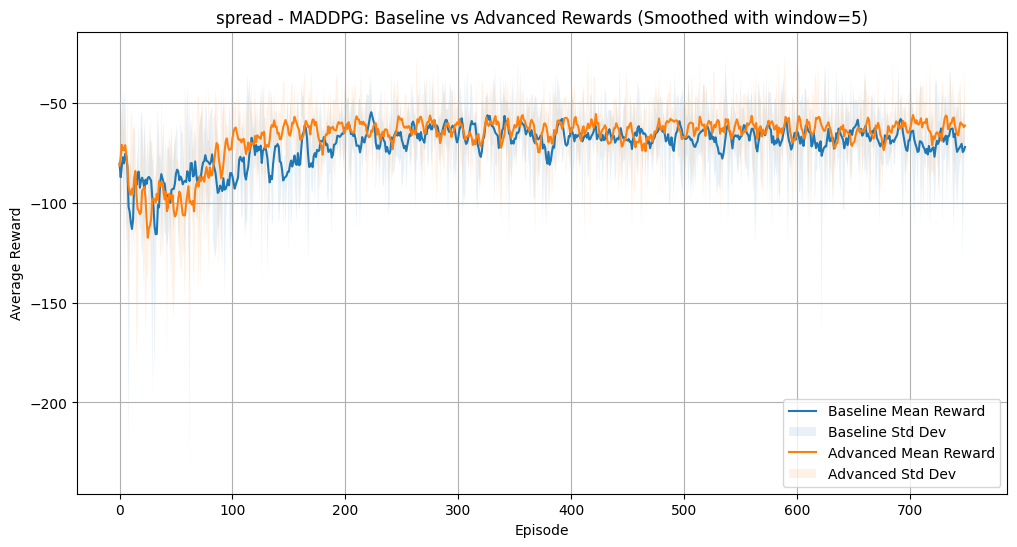

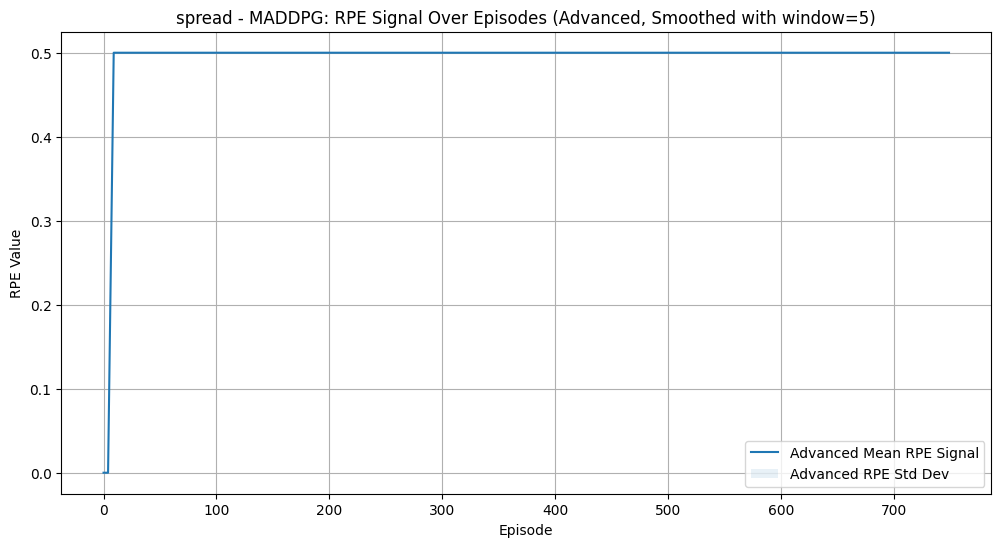

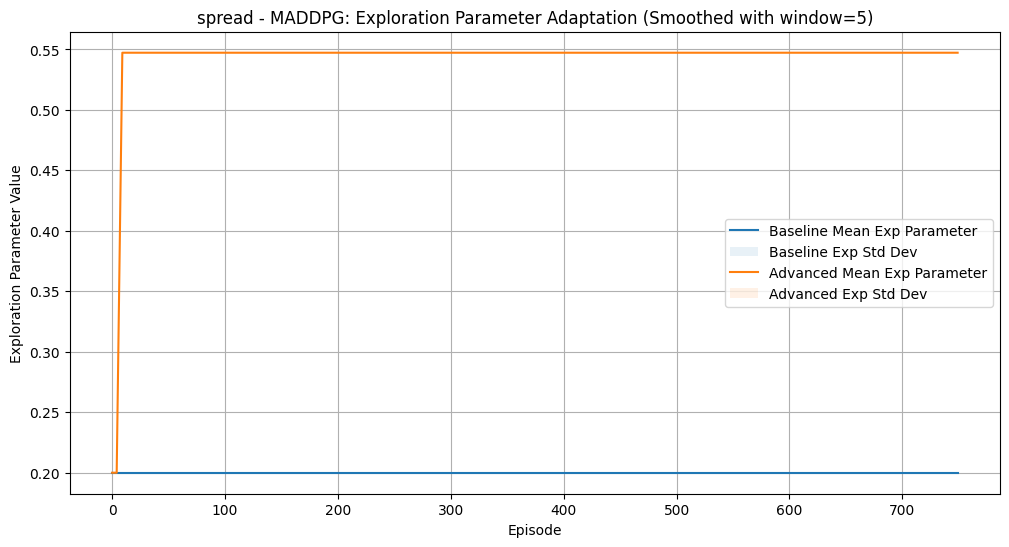

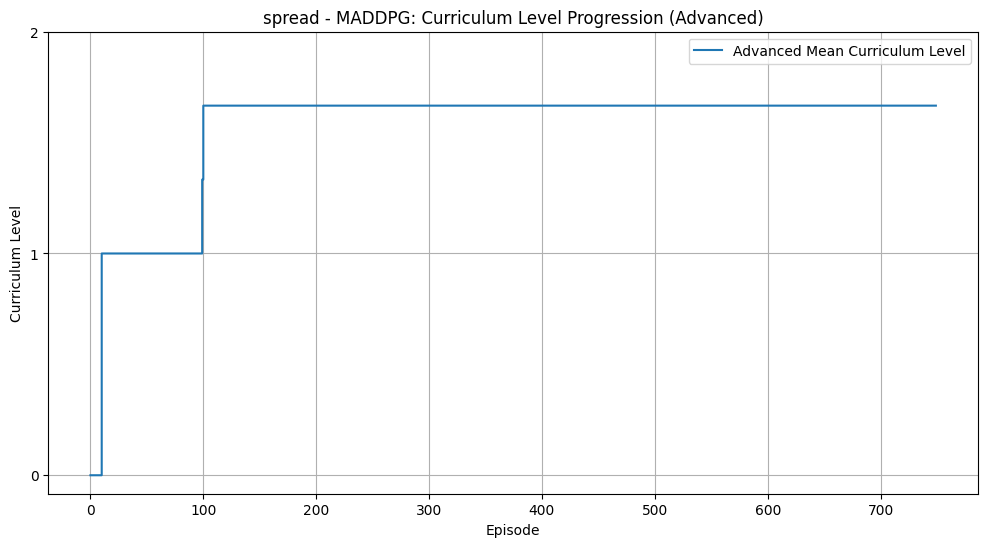


===== ENV=reference | ALGO=MADDPG ====
[reference | MADDPG | BASE] Episode 0 Reward=-74.13
[reference | MADDPG | BASE] Episode 100 Reward=-71.38
[reference | MADDPG | BASE] Episode 200 Reward=-52.16
[reference | MADDPG | BASE] Episode 300 Reward=-25.87
[reference | MADDPG | BASE] Episode 400 Reward=-25.93
[reference | MADDPG | BASE] Episode 500 Reward=-47.07
[reference | MADDPG | BASE] Episode 600 Reward=-31.58
[reference | MADDPG | BASE] Episode 700 Reward=-38.18
[reference | MADDPG | ADV] Episode 0 Reward=-72.52
Curriculum Level increased -> 1
[reference | MADDPG | ADV] Episode 100 Reward=-32.33
[reference | MADDPG | ADV] Episode 200 Reward=-27.03
[reference | MADDPG | ADV] Episode 300 Reward=-62.07
[reference | MADDPG | ADV] Episode 400 Reward=-54.61
[reference | MADDPG | ADV] Episode 500 Reward=-51.49
[reference | MADDPG | ADV] Episode 600 Reward=-65.96
[reference | MADDPG | ADV] Episode 700 Reward=-40.51
[reference | MADDPG | BASE] Episode 0 Reward=-35.46
[reference | MADDPG | BA

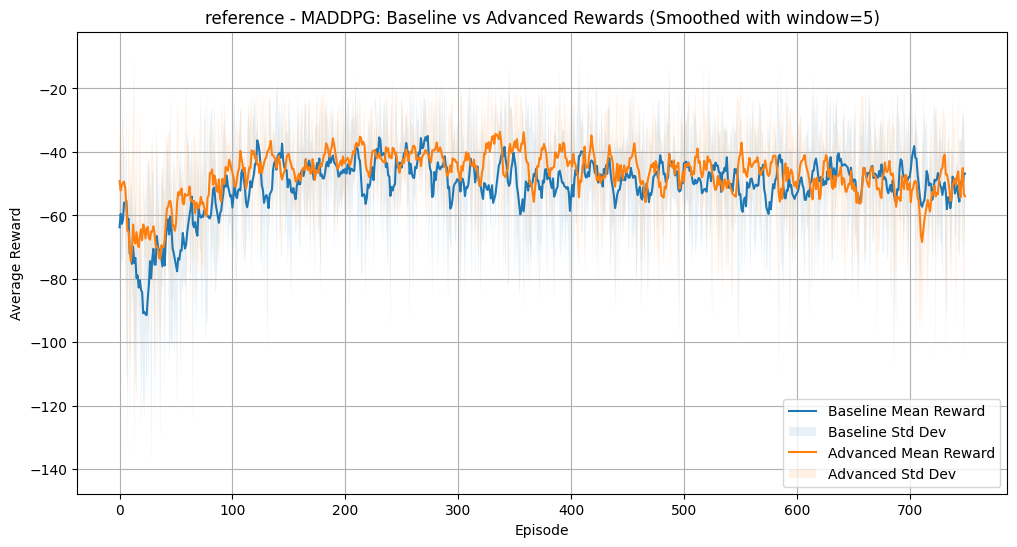

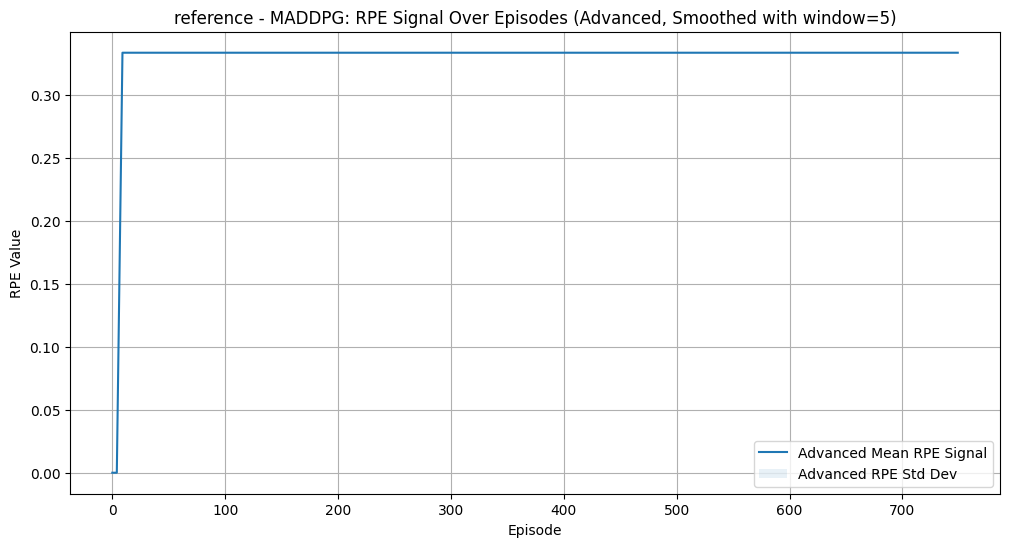

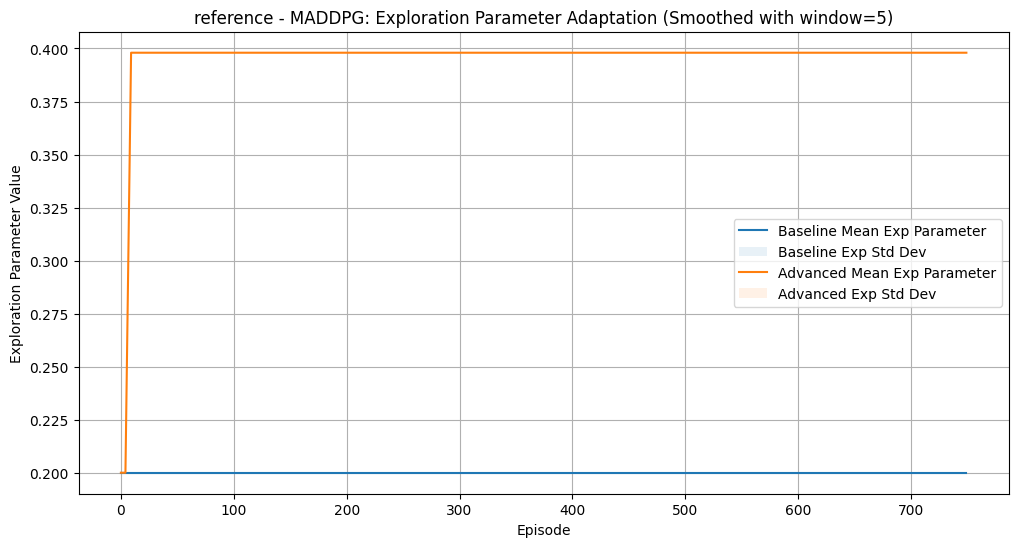

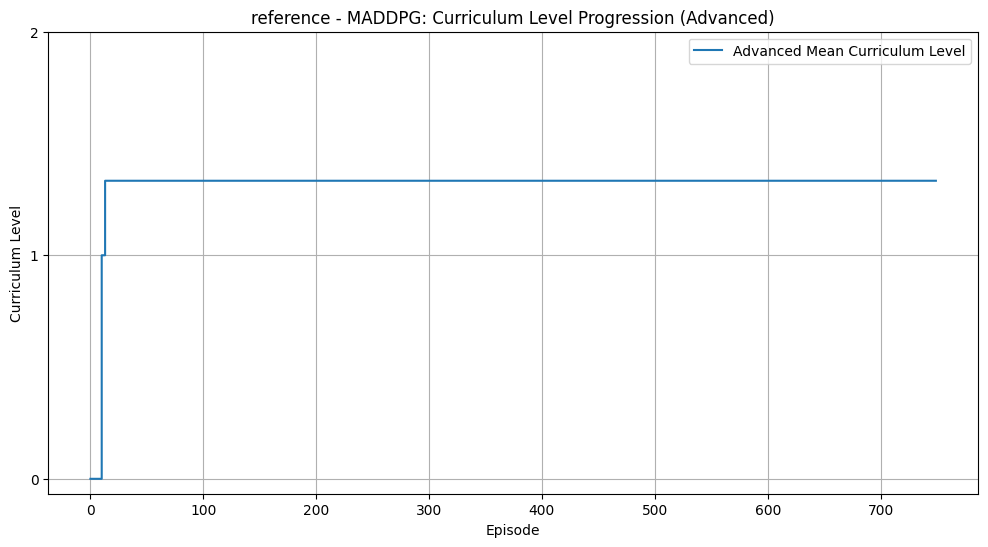


===== ENV=speaker_listener | ALGO=MADDPG ====
[speaker_listener | MADDPG | BASE] Episode 0 Reward=-85.41
[speaker_listener | MADDPG | BASE] Episode 100 Reward=-16.35
[speaker_listener | MADDPG | BASE] Episode 200 Reward=-22.84
[speaker_listener | MADDPG | BASE] Episode 300 Reward=-23.96
[speaker_listener | MADDPG | BASE] Episode 400 Reward=-25.18
[speaker_listener | MADDPG | BASE] Episode 500 Reward=-50.51
[speaker_listener | MADDPG | BASE] Episode 600 Reward=-52.75
[speaker_listener | MADDPG | BASE] Episode 700 Reward=-2.48
[speaker_listener | MADDPG | ADV] Episode 0 Reward=-91.12
Curriculum Level increased -> 1
Curriculum Level increased -> 2
Curriculum Level increased -> 3
[speaker_listener | MADDPG | ADV] Episode 100 Reward=-82.93
[speaker_listener | MADDPG | ADV] Episode 200 Reward=-22.22
[speaker_listener | MADDPG | ADV] Episode 300 Reward=-143.84
[speaker_listener | MADDPG | ADV] Episode 400 Reward=-72.57
[speaker_listener | MADDPG | ADV] Episode 500 Reward=-25.17
[speaker_list

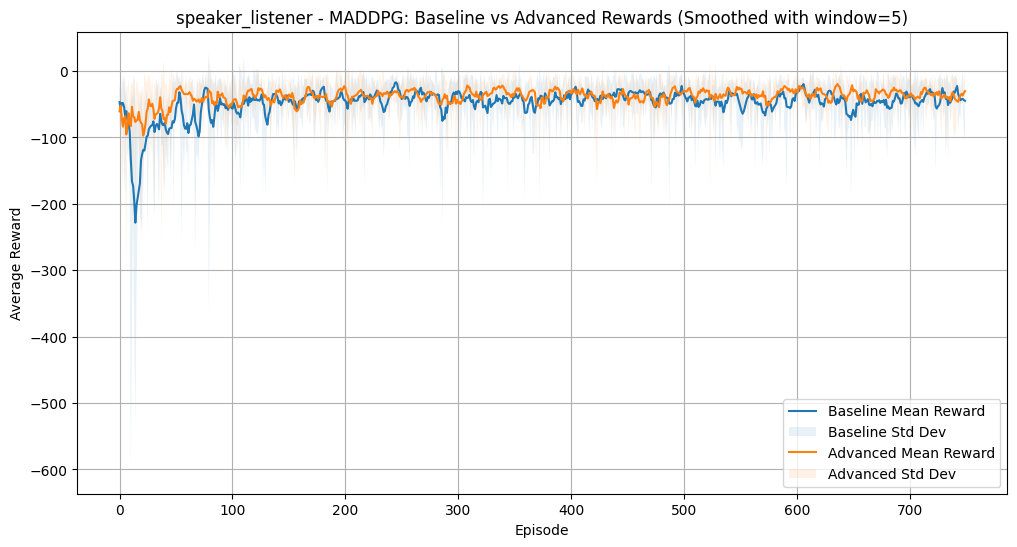

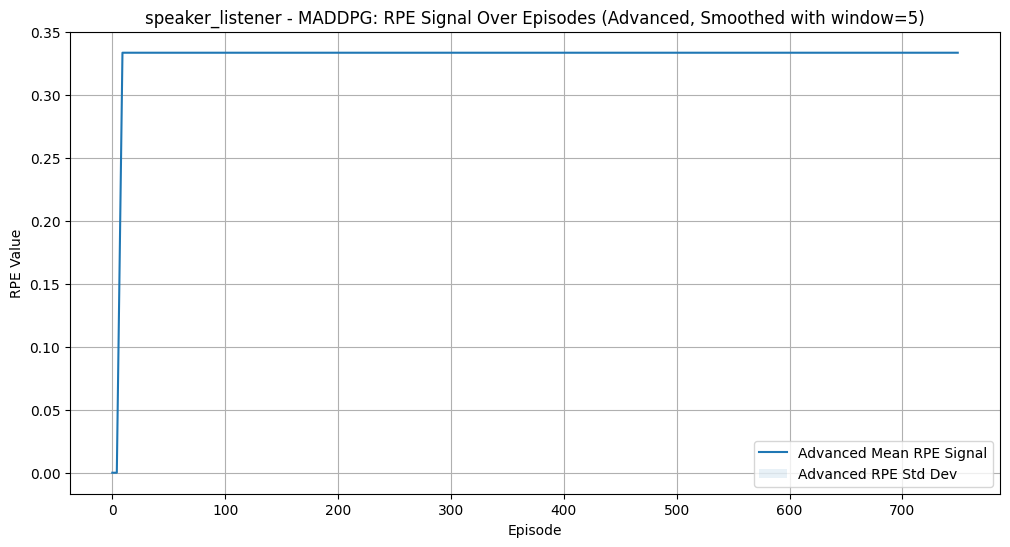

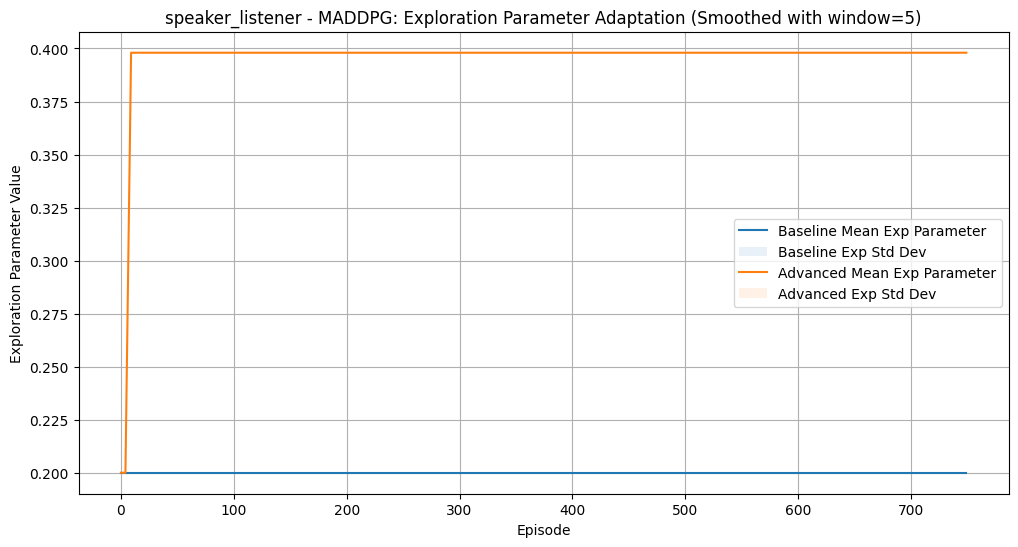

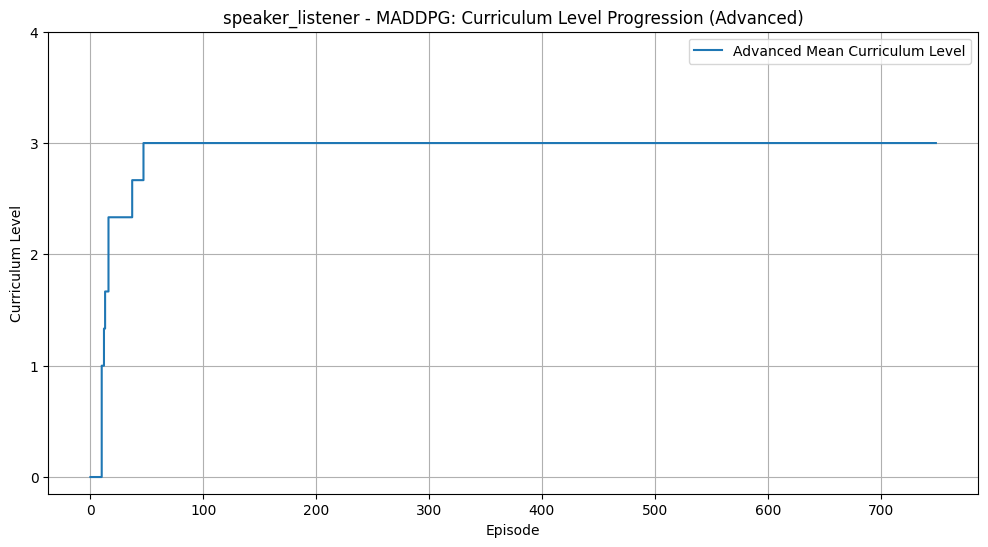

In [ ]:
print("\n--- Running MADDPG with new test parameters ---")
evaluate_algorithm(
    algo_name="MADDPG",
    envs=envs_all,
    seeds=[0,1,2],
    episodes=750,
    max_steps=25
)


--- Running MASAC with new test parameters ---

===== ENV=spread | ALGO=MASAC ====
[spread | MASAC | BASE] Episode 0 Reward=-51.09
[spread | MASAC | BASE] Episode 100 Reward=-80.23
[spread | MASAC | BASE] Episode 200 Reward=-119.28
[spread | MASAC | BASE] Episode 300 Reward=-115.14
[spread | MASAC | BASE] Episode 400 Reward=-128.30
[spread | MASAC | BASE] Episode 500 Reward=-68.44
[spread | MASAC | BASE] Episode 600 Reward=-152.31
[spread | MASAC | BASE] Episode 700 Reward=-80.52
[spread | MASAC | ADV] Episode 0 Reward=-86.96
Curriculum Level increased -> 1
[spread | MASAC | ADV] Episode 100 Reward=-126.96
[spread | MASAC | ADV] Episode 200 Reward=-83.95
[spread | MASAC | ADV] Episode 300 Reward=-140.42
[spread | MASAC | ADV] Episode 400 Reward=-67.40
[spread | MASAC | ADV] Episode 500 Reward=-106.65
[spread | MASAC | ADV] Episode 600 Reward=-89.57
Curriculum Level increased -> 2
[spread | MASAC | ADV] Episode 700 Reward=-92.42
[spread | MASAC | BASE] Episode 0 Reward=-42.79
[spread |

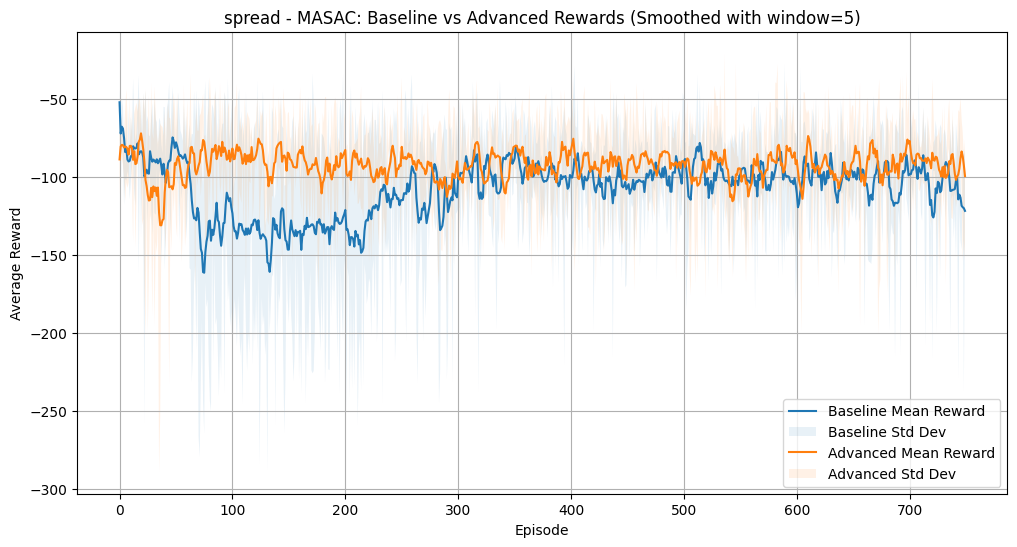

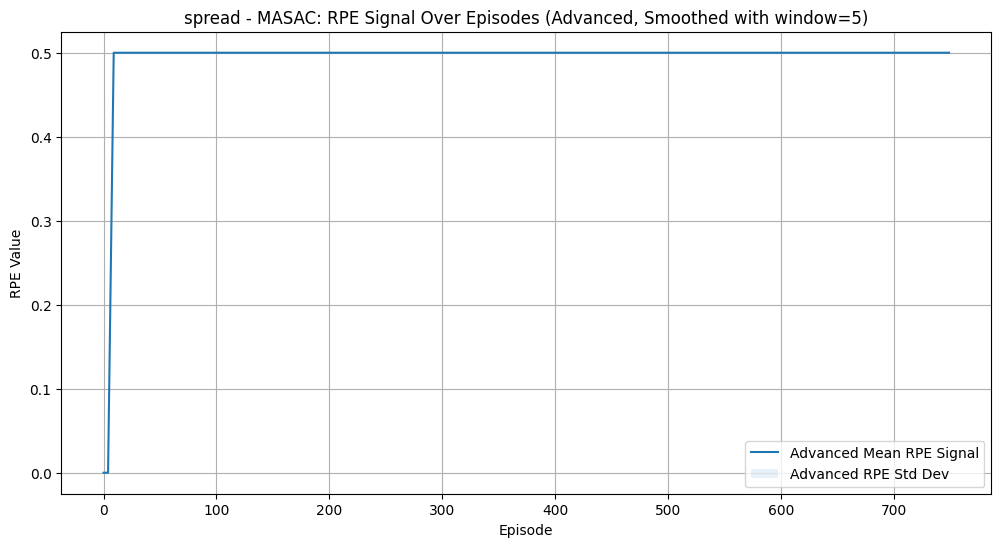

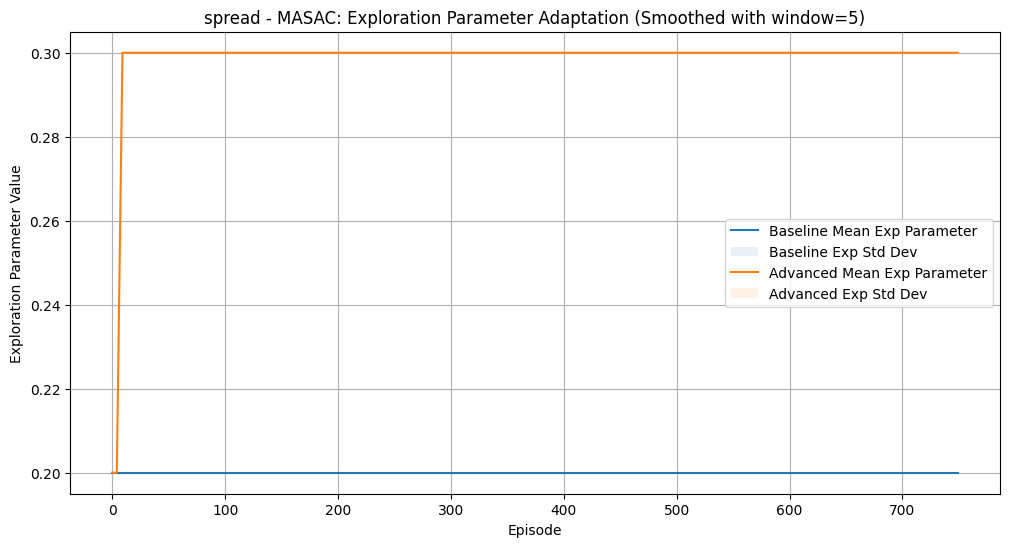

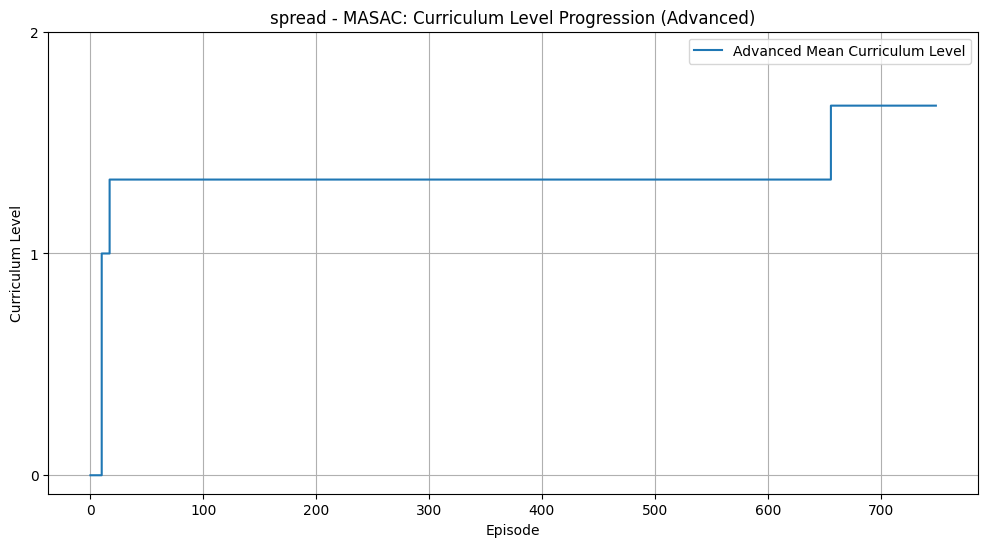


===== ENV=reference | ALGO=MASAC ====
[reference | MASAC | BASE] Episode 0 Reward=-51.88
[reference | MASAC | BASE] Episode 100 Reward=-211.77
[reference | MASAC | BASE] Episode 200 Reward=-145.44
[reference | MASAC | BASE] Episode 300 Reward=-142.55
[reference | MASAC | BASE] Episode 400 Reward=-129.19
[reference | MASAC | BASE] Episode 500 Reward=-176.60
[reference | MASAC | BASE] Episode 600 Reward=-119.77
[reference | MASAC | BASE] Episode 700 Reward=-100.99
[reference | MASAC | ADV] Episode 0 Reward=-10.88
Curriculum Level increased -> 1
[reference | MASAC | ADV] Episode 100 Reward=-101.47
[reference | MASAC | ADV] Episode 200 Reward=-86.82
[reference | MASAC | ADV] Episode 300 Reward=-107.77
[reference | MASAC | ADV] Episode 400 Reward=-118.84
[reference | MASAC | ADV] Episode 500 Reward=-97.56
[reference | MASAC | ADV] Episode 600 Reward=-65.80
[reference | MASAC | ADV] Episode 700 Reward=-86.22
[reference | MASAC | BASE] Episode 0 Reward=-25.38
[reference | MASAC | BASE] Episo

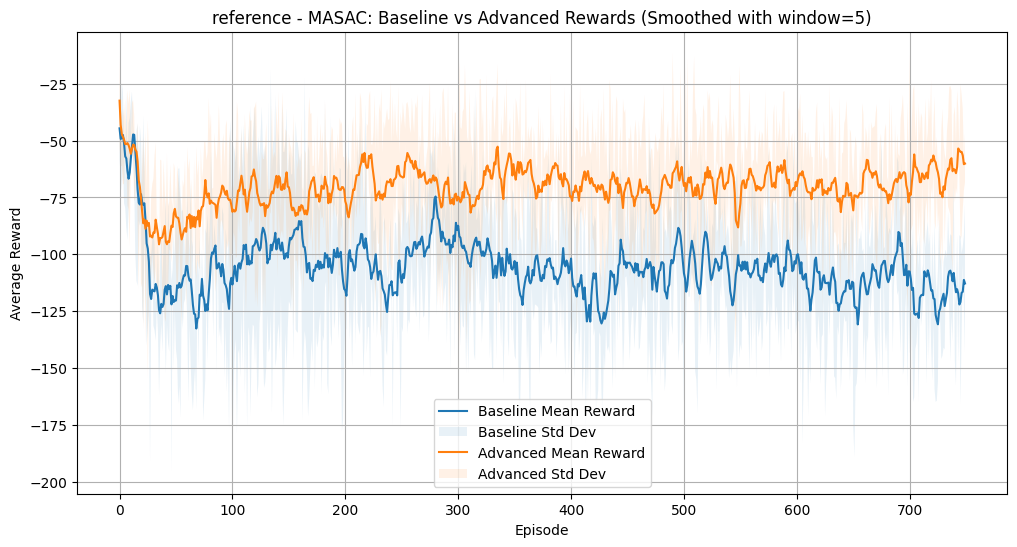

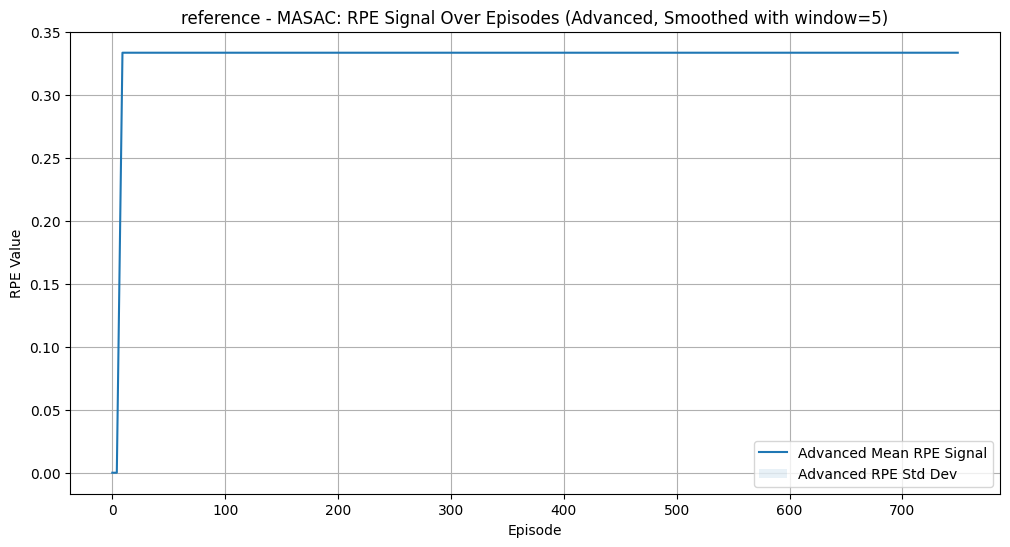

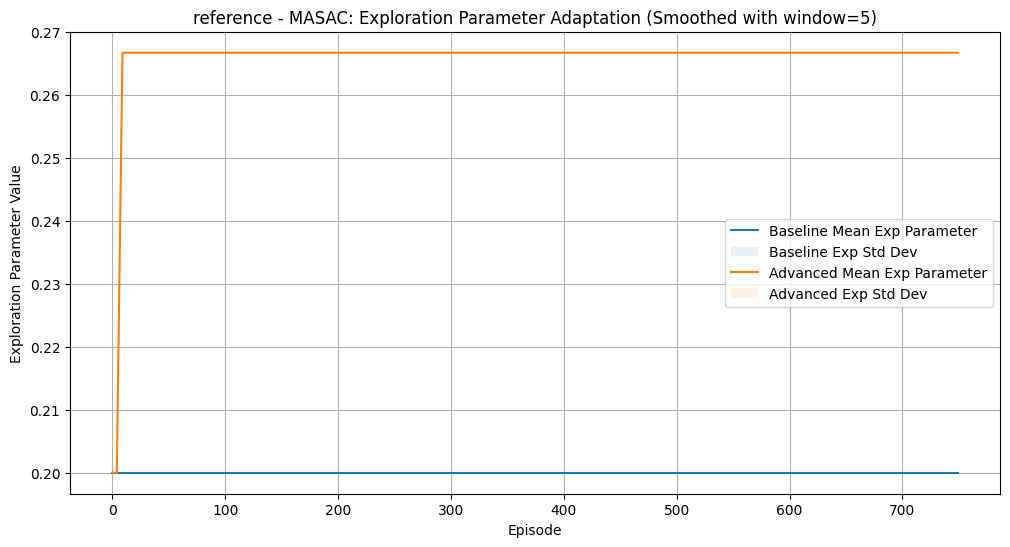

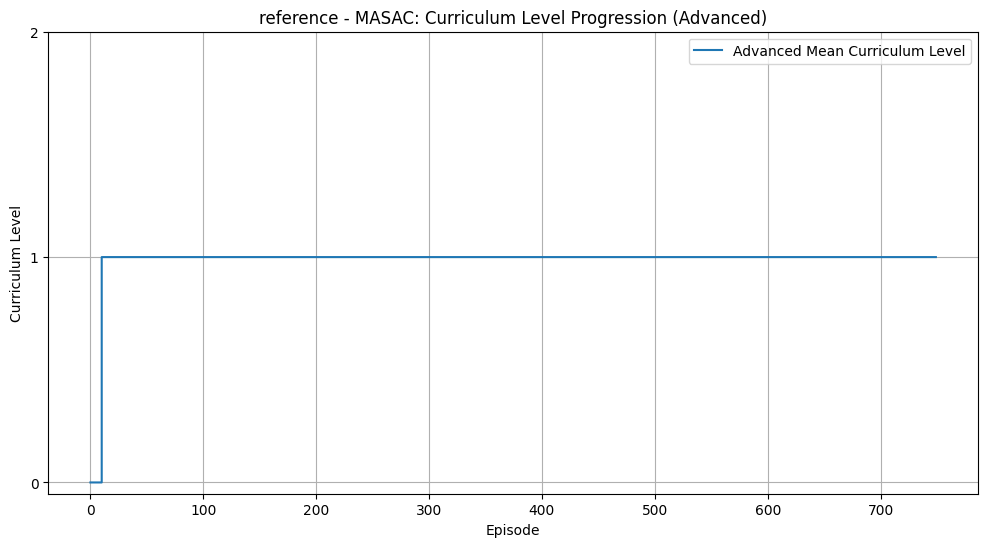


===== ENV=speaker_listener | ALGO=MASAC ====
[speaker_listener | MASAC | BASE] Episode 0 Reward=-82.85
[speaker_listener | MASAC | BASE] Episode 100 Reward=-144.57
[speaker_listener | MASAC | BASE] Episode 200 Reward=-12.48
[speaker_listener | MASAC | BASE] Episode 300 Reward=-65.41
[speaker_listener | MASAC | BASE] Episode 400 Reward=-527.03
[speaker_listener | MASAC | BASE] Episode 500 Reward=-606.12
[speaker_listener | MASAC | BASE] Episode 600 Reward=-15.58
[speaker_listener | MASAC | BASE] Episode 700 Reward=-11.99
[speaker_listener | MASAC | ADV] Episode 0 Reward=-64.54
Curriculum Level increased -> 1
Curriculum Level increased -> 2
Curriculum Level increased -> 3
[speaker_listener | MASAC | ADV] Episode 100 Reward=-39.27
[speaker_listener | MASAC | ADV] Episode 200 Reward=-248.46
[speaker_listener | MASAC | ADV] Episode 300 Reward=-175.56
[speaker_listener | MASAC | ADV] Episode 400 Reward=-187.68
[speaker_listener | MASAC | ADV] Episode 500 Reward=-27.87
[speaker_listener | MA

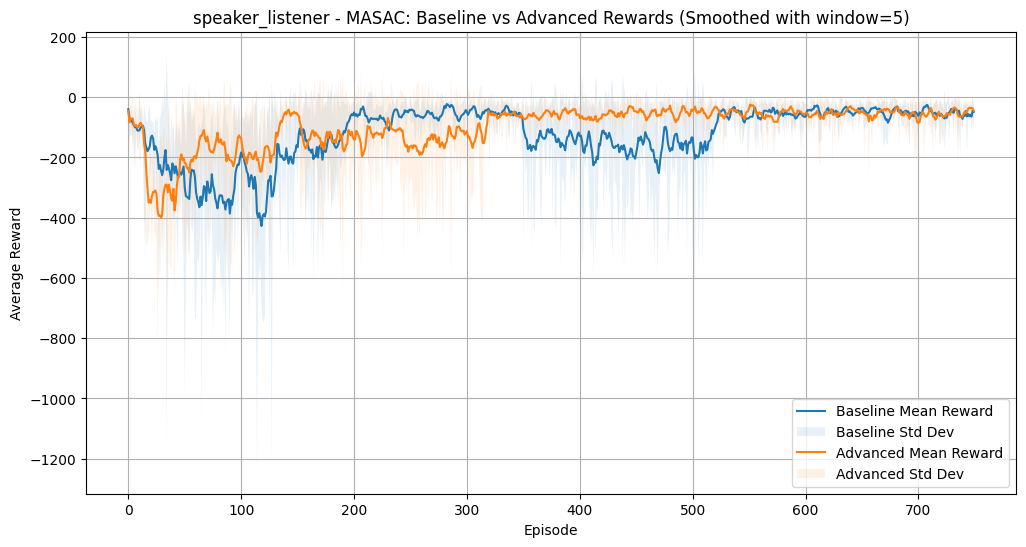

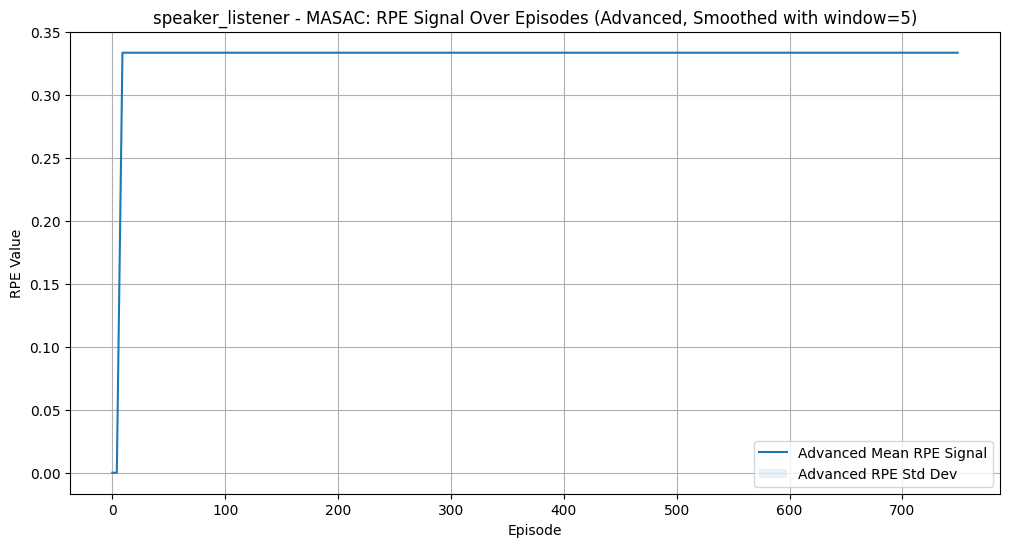

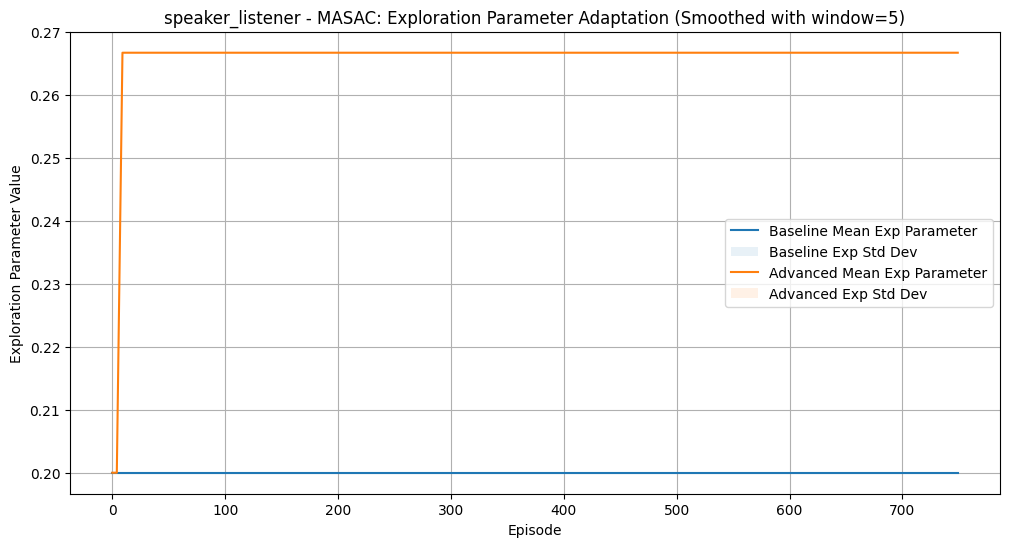

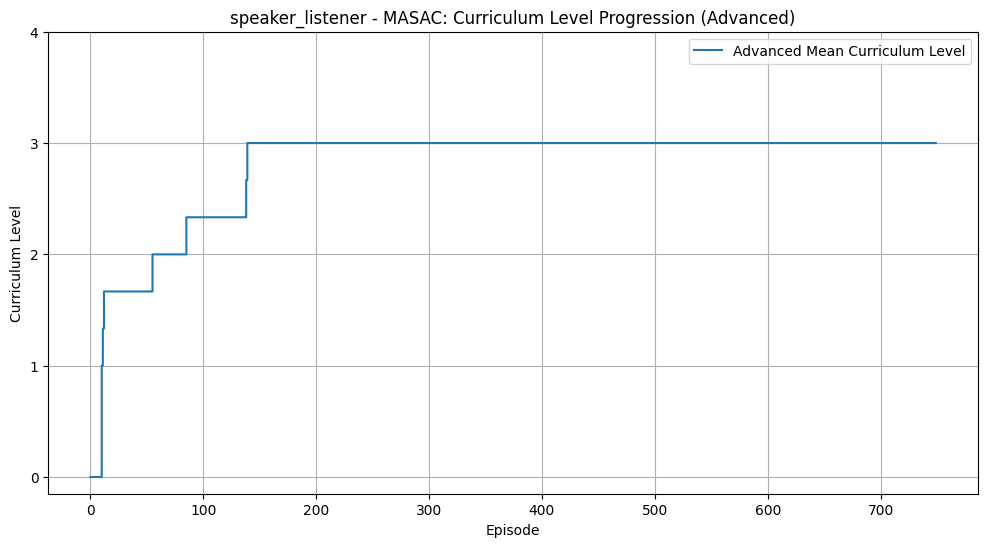

In [ ]:
print("\n--- Running MASAC with new test parameters ---")
evaluate_algorithm(
    algo_name="MASAC",
    envs=envs_all,
    seeds=[0,1,2],
    episodes=750,
    max_steps=25
)


--- Running IPPO with new test parameters ---

===== ENV=spread | ALGO=IPPO ====
[spread | IPPO | BASE] Episode 0 Reward=-43.72
[spread | IPPO | BASE] Episode 100 Reward=-86.50
[spread | IPPO | BASE] Episode 200 Reward=-48.30
[spread | IPPO | BASE] Episode 300 Reward=-110.47
[spread | IPPO | BASE] Episode 400 Reward=-67.84
[spread | IPPO | BASE] Episode 500 Reward=-99.97
[spread | IPPO | BASE] Episode 600 Reward=-93.27
[spread | IPPO | BASE] Episode 700 Reward=-53.75
[spread | IPPO | BASE] Episode 800 Reward=-102.91
[spread | IPPO | BASE] Episode 900 Reward=-54.70
[spread | IPPO | ADV] Episode 0 Reward=-48.32
Curriculum Level increased -> 1
[spread | IPPO | ADV] Episode 100 Reward=-144.19
[spread | IPPO | ADV] Episode 200 Reward=-80.56
[spread | IPPO | ADV] Episode 300 Reward=-92.36
[spread | IPPO | ADV] Episode 400 Reward=-87.78
[spread | IPPO | ADV] Episode 500 Reward=-106.05
Curriculum Level increased -> 2
[spread | IPPO | ADV] Episode 600 Reward=-61.36
[spread | IPPO | ADV] Episod

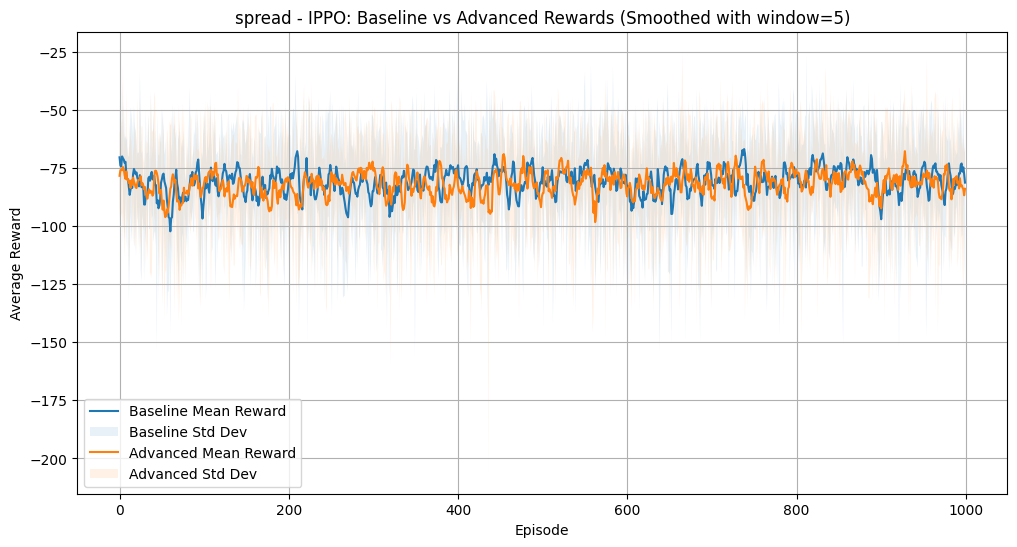

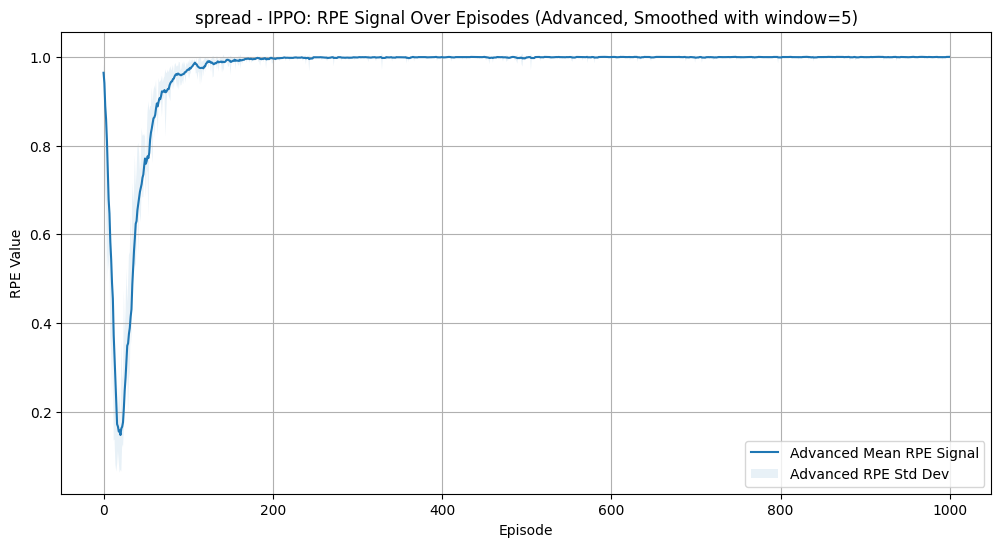

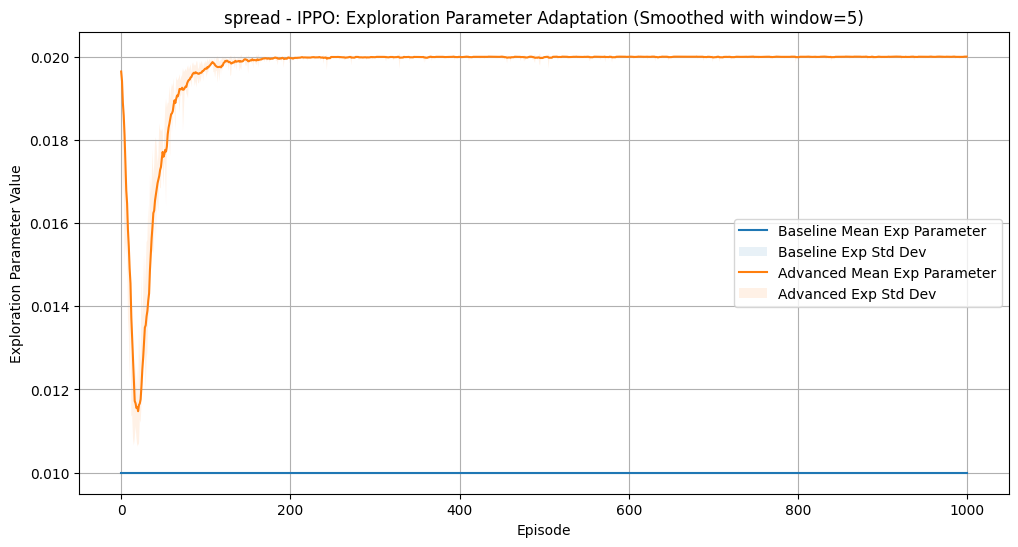

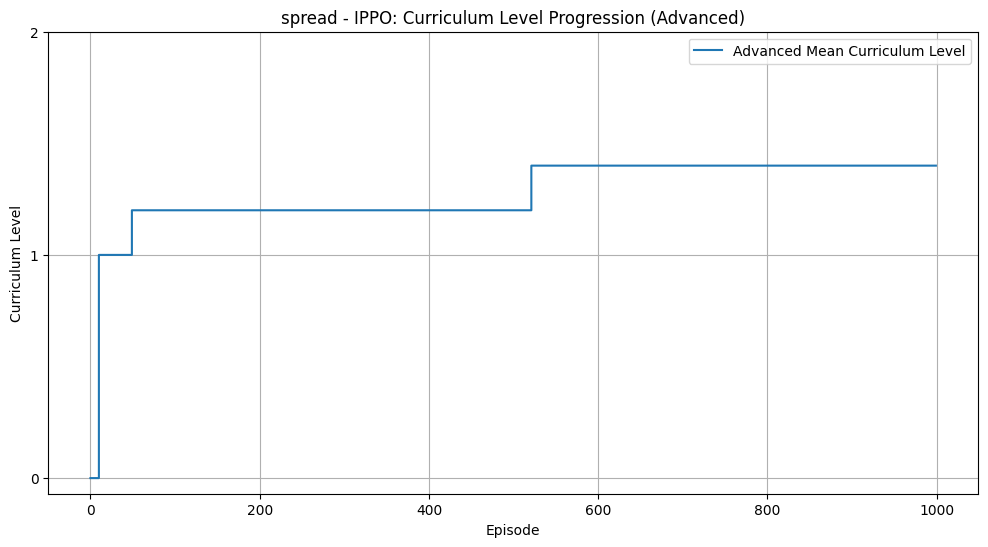


===== ENV=reference | ALGO=IPPO ====
[reference | IPPO | BASE] Episode 0 Reward=-32.72
[reference | IPPO | BASE] Episode 100 Reward=-50.35
[reference | IPPO | BASE] Episode 200 Reward=-43.47
[reference | IPPO | BASE] Episode 300 Reward=-68.08
[reference | IPPO | BASE] Episode 400 Reward=-93.11
[reference | IPPO | BASE] Episode 500 Reward=-35.14
[reference | IPPO | BASE] Episode 600 Reward=-66.63
[reference | IPPO | BASE] Episode 700 Reward=-61.10
[reference | IPPO | BASE] Episode 800 Reward=-81.93
[reference | IPPO | BASE] Episode 900 Reward=-28.15
[reference | IPPO | ADV] Episode 0 Reward=-55.25
Curriculum Level increased -> 1
Curriculum Level increased -> 2
[reference | IPPO | ADV] Episode 100 Reward=-42.77
[reference | IPPO | ADV] Episode 200 Reward=-41.32
[reference | IPPO | ADV] Episode 300 Reward=-68.28
[reference | IPPO | ADV] Episode 400 Reward=-59.63
[reference | IPPO | ADV] Episode 500 Reward=-60.83
[reference | IPPO | ADV] Episode 600 Reward=-64.32
[reference | IPPO | ADV] 

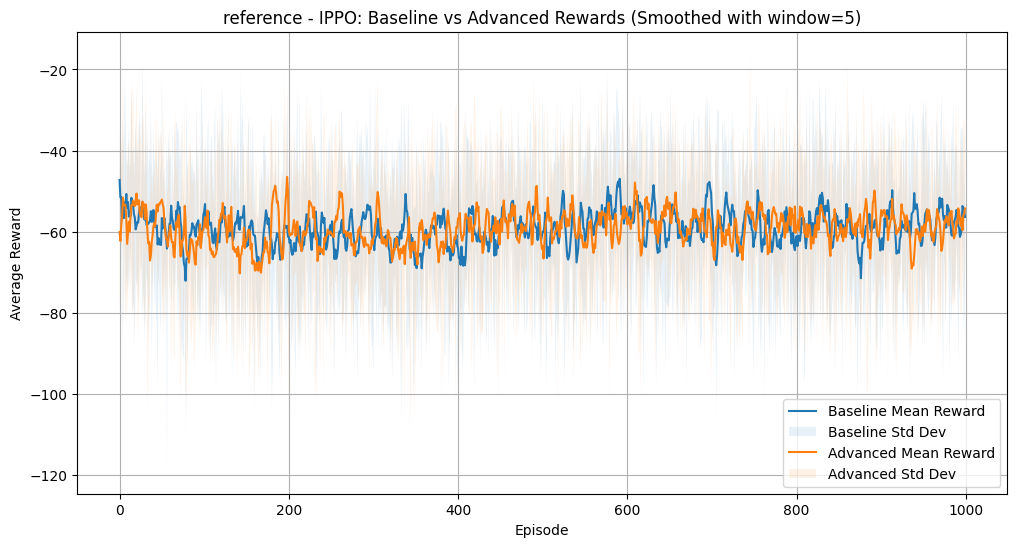

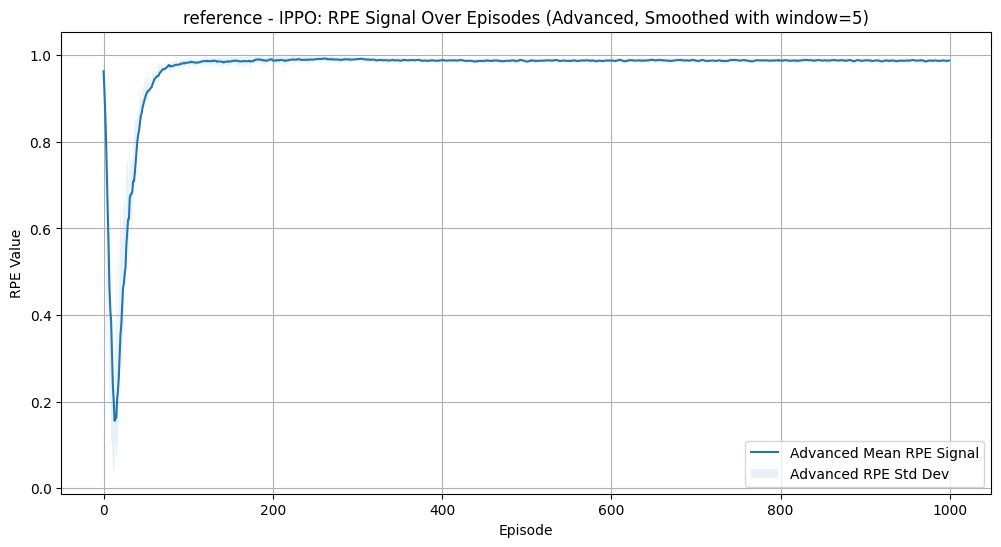

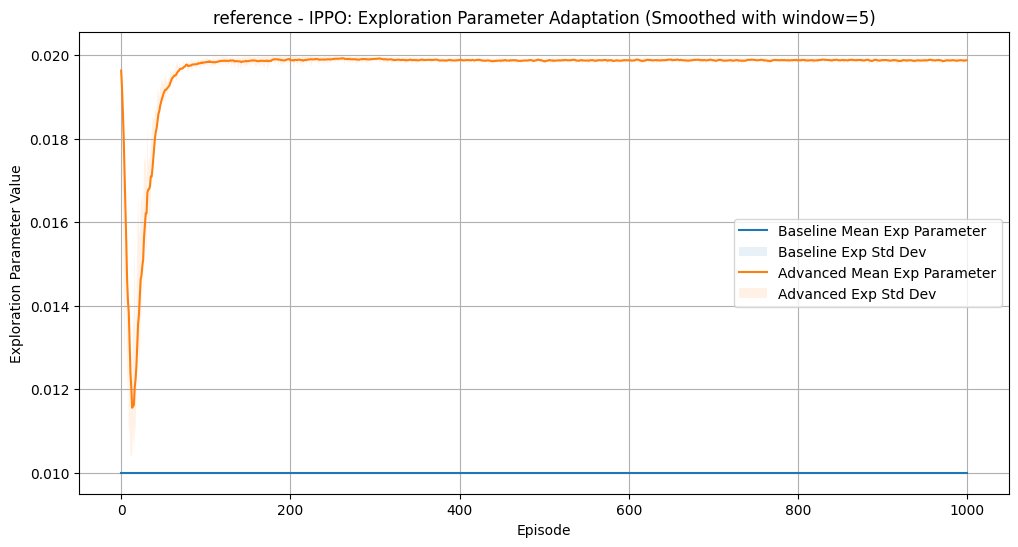

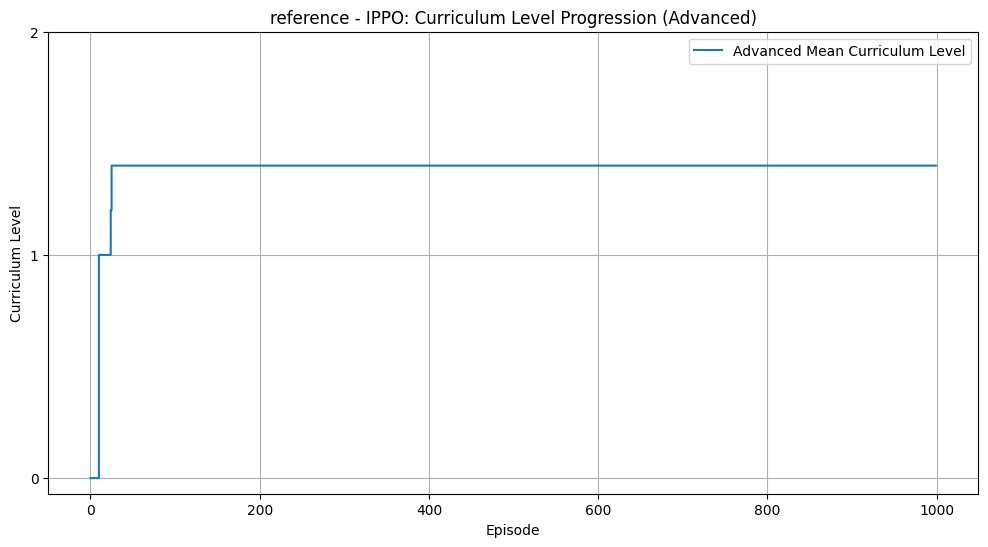


===== ENV=speaker_listener | ALGO=IPPO ====
[speaker_listener | IPPO | BASE] Episode 0 Reward=-54.83
[speaker_listener | IPPO | BASE] Episode 100 Reward=-99.84
[speaker_listener | IPPO | BASE] Episode 200 Reward=-95.15
[speaker_listener | IPPO | BASE] Episode 300 Reward=-75.77
[speaker_listener | IPPO | BASE] Episode 400 Reward=-85.84
[speaker_listener | IPPO | BASE] Episode 500 Reward=-251.43
[speaker_listener | IPPO | BASE] Episode 600 Reward=-38.62
[speaker_listener | IPPO | BASE] Episode 700 Reward=-113.37
[speaker_listener | IPPO | BASE] Episode 800 Reward=-115.90
[speaker_listener | IPPO | BASE] Episode 900 Reward=-191.10
[speaker_listener | IPPO | ADV] Episode 0 Reward=-85.49
Curriculum Level increased -> 1
Curriculum Level increased -> 2
Curriculum Level increased -> 3
[speaker_listener | IPPO | ADV] Episode 100 Reward=-4.97
[speaker_listener | IPPO | ADV] Episode 200 Reward=-112.37
[speaker_listener | IPPO | ADV] Episode 300 Reward=-75.46
[speaker_listener | IPPO | ADV] Episo

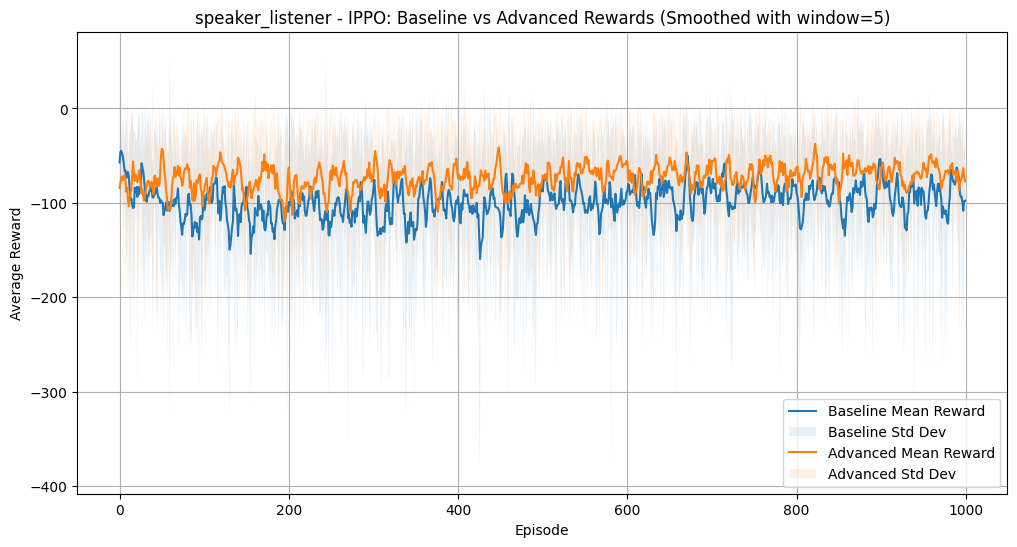

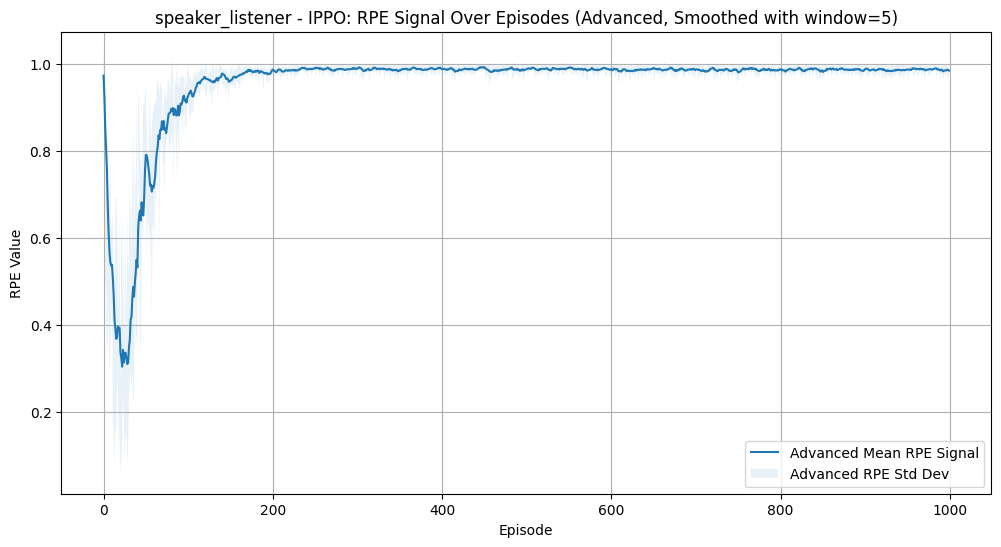

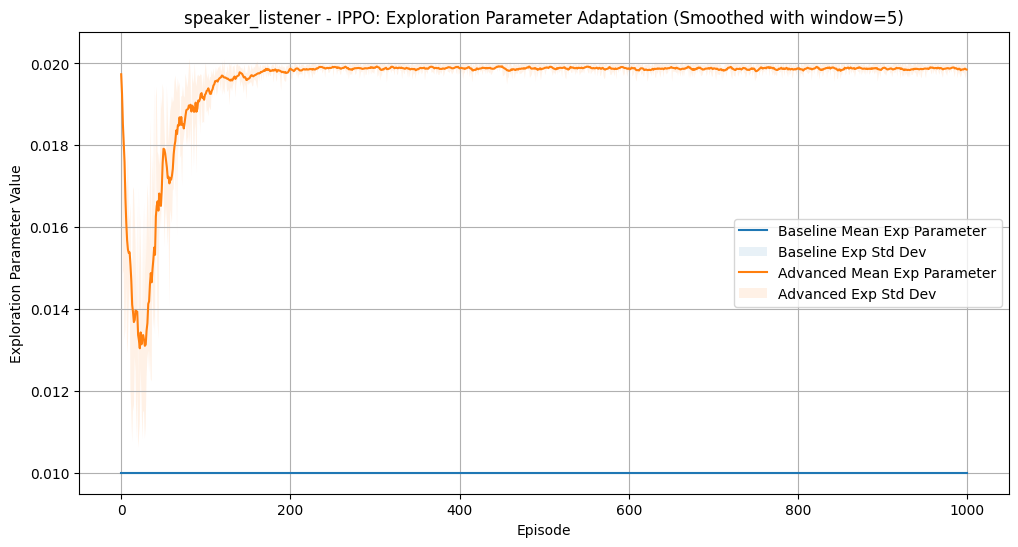

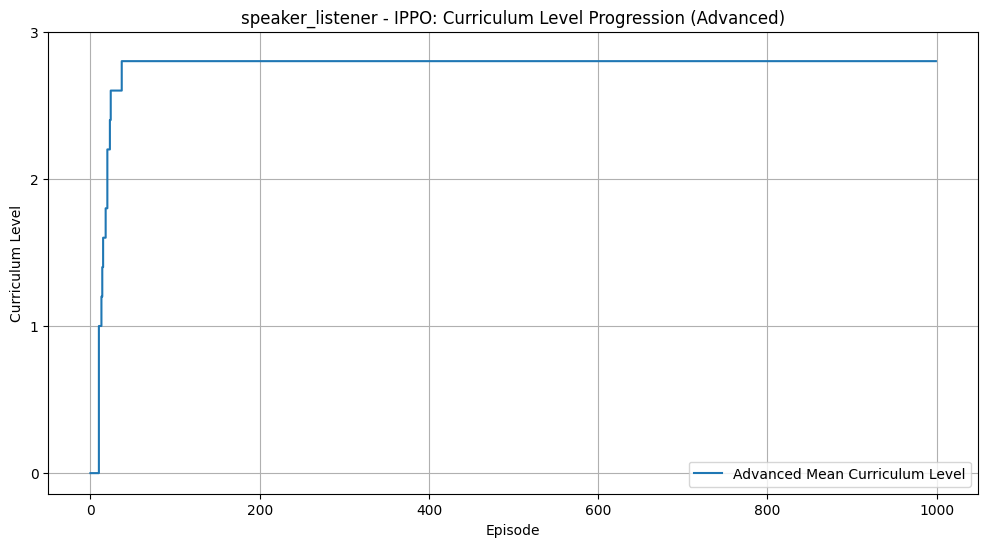

In [ ]:
print("\n--- Running IPPO with new test parameters ---")
evaluate_algorithm(
    algo_name="IPPO",
    envs=envs_all,
    seeds=[0,1,2,3,4],
    episodes=1000,
    max_steps=25
)


--- Running CPPO with new test parameters ---

===== ENV=spread | ALGO=CPPO ====
[spread | CPPO | BASE] Episode 0 Reward=-182.37
[spread | CPPO | BASE] Episode 100 Reward=-68.10
[spread | CPPO | BASE] Episode 200 Reward=-96.91
[spread | CPPO | BASE] Episode 300 Reward=-80.63
[spread | CPPO | BASE] Episode 400 Reward=-87.58
[spread | CPPO | BASE] Episode 500 Reward=-66.78
[spread | CPPO | BASE] Episode 600 Reward=-64.63
[spread | CPPO | BASE] Episode 700 Reward=-118.56
[spread | CPPO | BASE] Episode 800 Reward=-72.32
[spread | CPPO | BASE] Episode 900 Reward=-65.21
[spread | CPPO | ADV] Episode 0 Reward=-61.54
Curriculum Level increased -> 1
[spread | CPPO | ADV] Episode 100 Reward=-90.10
[spread | CPPO | ADV] Episode 200 Reward=-92.11
[spread | CPPO | ADV] Episode 300 Reward=-62.09
[spread | CPPO | ADV] Episode 400 Reward=-68.76
[spread | CPPO | ADV] Episode 500 Reward=-70.67
[spread | CPPO | ADV] Episode 600 Reward=-90.79
[spread | CPPO | ADV] Episode 700 Reward=-71.73
[spread | CPPO

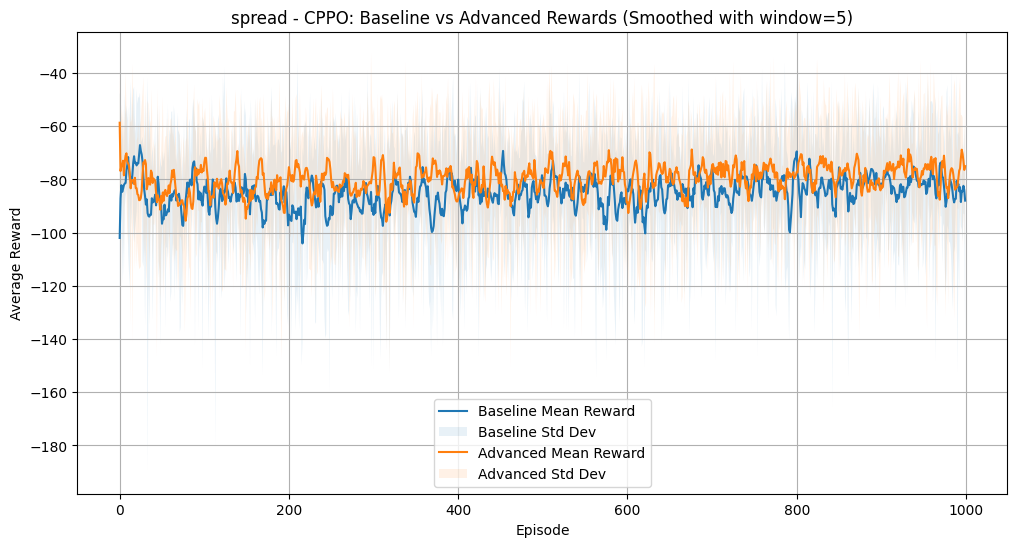

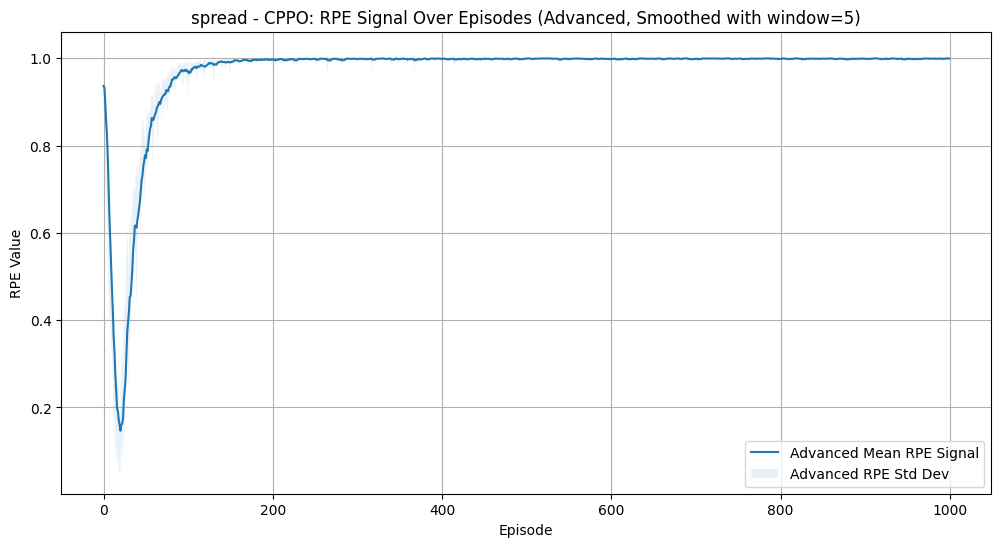

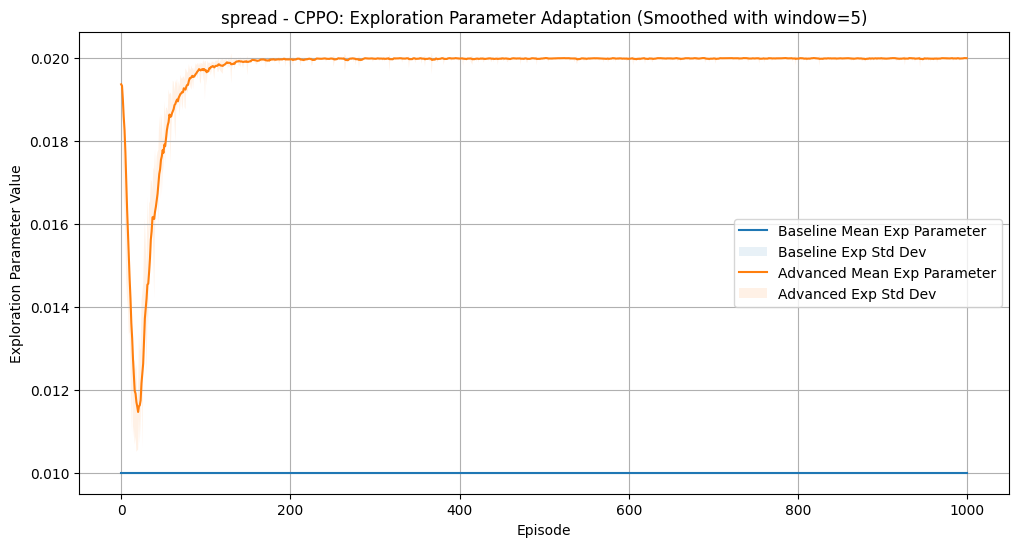

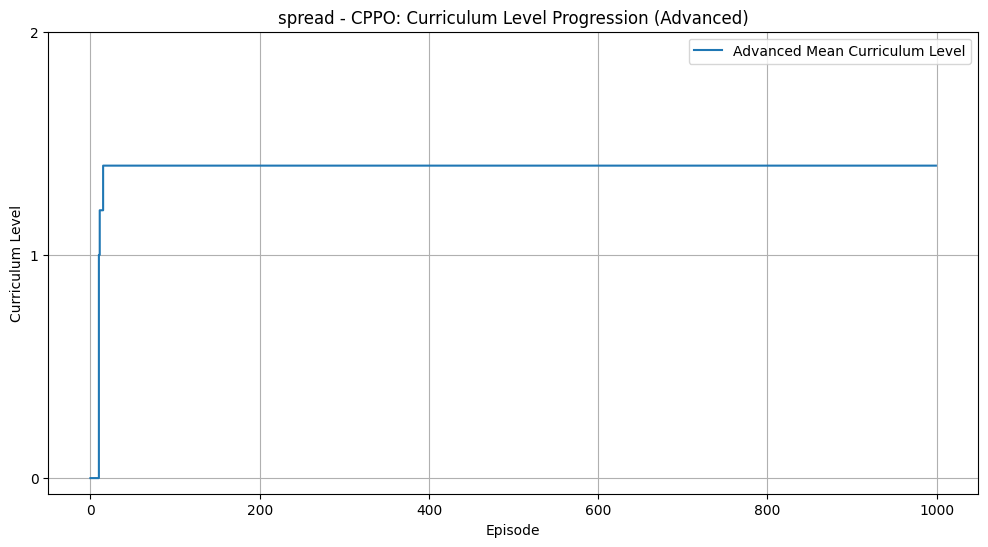


===== ENV=reference | ALGO=CPPO ====
[reference | CPPO | BASE] Episode 0 Reward=-29.19
[reference | CPPO | BASE] Episode 100 Reward=-66.23
[reference | CPPO | BASE] Episode 200 Reward=-38.74
[reference | CPPO | BASE] Episode 300 Reward=-89.86
[reference | CPPO | BASE] Episode 400 Reward=-39.86
[reference | CPPO | BASE] Episode 500 Reward=-39.44
[reference | CPPO | BASE] Episode 600 Reward=-59.83
[reference | CPPO | BASE] Episode 700 Reward=-83.10
[reference | CPPO | BASE] Episode 800 Reward=-57.77
[reference | CPPO | BASE] Episode 900 Reward=-89.23
[reference | CPPO | ADV] Episode 0 Reward=-52.16
Curriculum Level increased -> 1
[reference | CPPO | ADV] Episode 100 Reward=-49.64
[reference | CPPO | ADV] Episode 200 Reward=-60.16
[reference | CPPO | ADV] Episode 300 Reward=-42.61
[reference | CPPO | ADV] Episode 400 Reward=-70.81
[reference | CPPO | ADV] Episode 500 Reward=-70.48
[reference | CPPO | ADV] Episode 600 Reward=-52.23
[reference | CPPO | ADV] Episode 700 Reward=-26.91
[refer

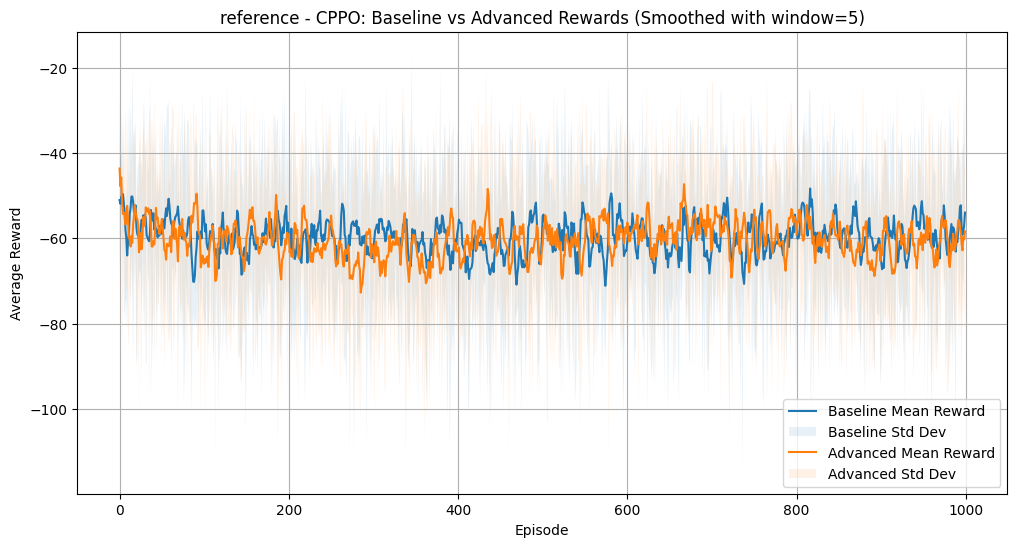

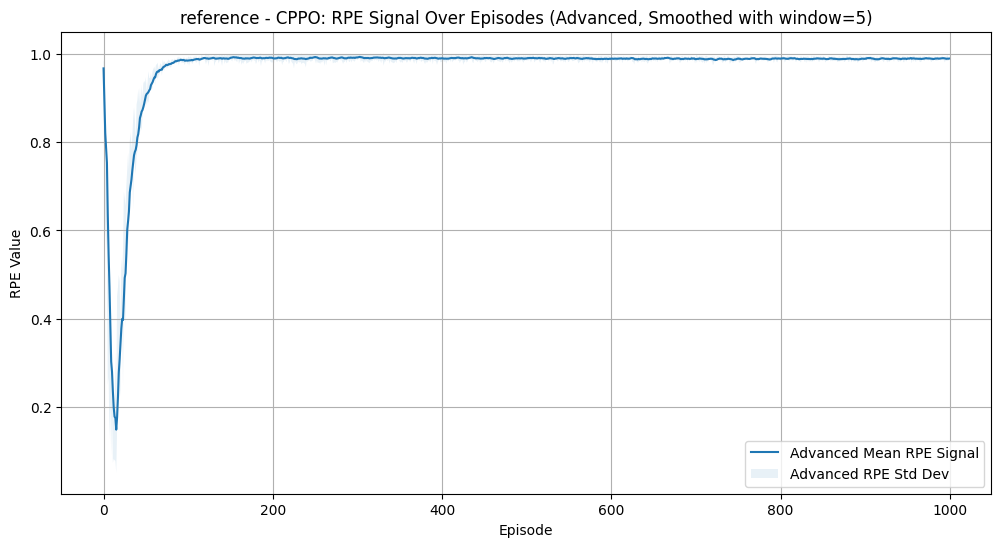

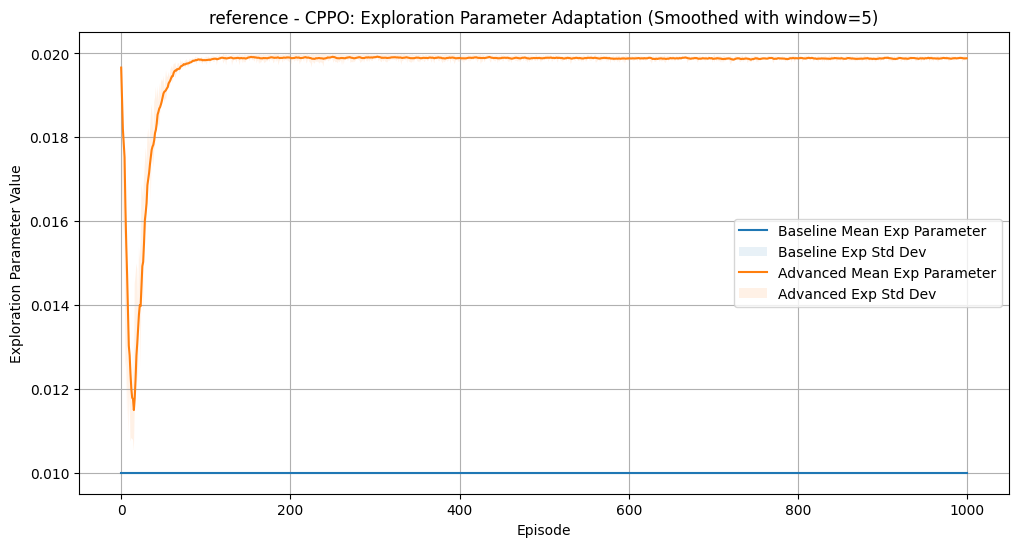

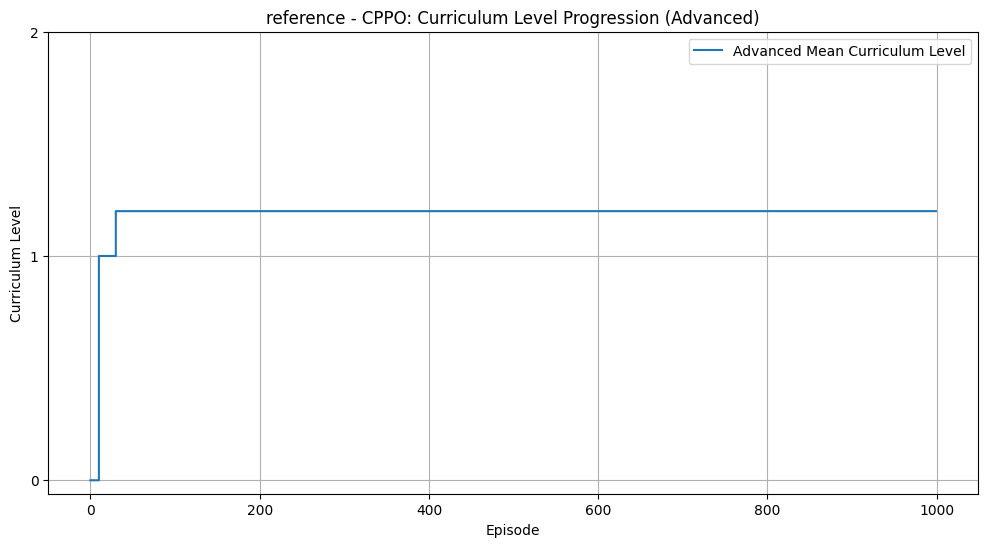


===== ENV=speaker_listener | ALGO=CPPO ====
[speaker_listener | CPPO | BASE] Episode 0 Reward=-40.10
[speaker_listener | CPPO | BASE] Episode 100 Reward=-105.14
[speaker_listener | CPPO | BASE] Episode 200 Reward=-7.08
[speaker_listener | CPPO | BASE] Episode 300 Reward=-98.35
[speaker_listener | CPPO | BASE] Episode 400 Reward=-28.85
[speaker_listener | CPPO | BASE] Episode 500 Reward=-8.76
[speaker_listener | CPPO | BASE] Episode 600 Reward=-32.56
[speaker_listener | CPPO | BASE] Episode 700 Reward=-18.96
[speaker_listener | CPPO | BASE] Episode 800 Reward=-0.70
[speaker_listener | CPPO | BASE] Episode 900 Reward=-63.64
[speaker_listener | CPPO | ADV] Episode 0 Reward=-93.06
Curriculum Level increased -> 1
Curriculum Level increased -> 2
Curriculum Level increased -> 3
[speaker_listener | CPPO | ADV] Episode 100 Reward=-16.67
[speaker_listener | CPPO | ADV] Episode 200 Reward=-220.12
[speaker_listener | CPPO | ADV] Episode 300 Reward=-19.26
[speaker_listener | CPPO | ADV] Episode 40

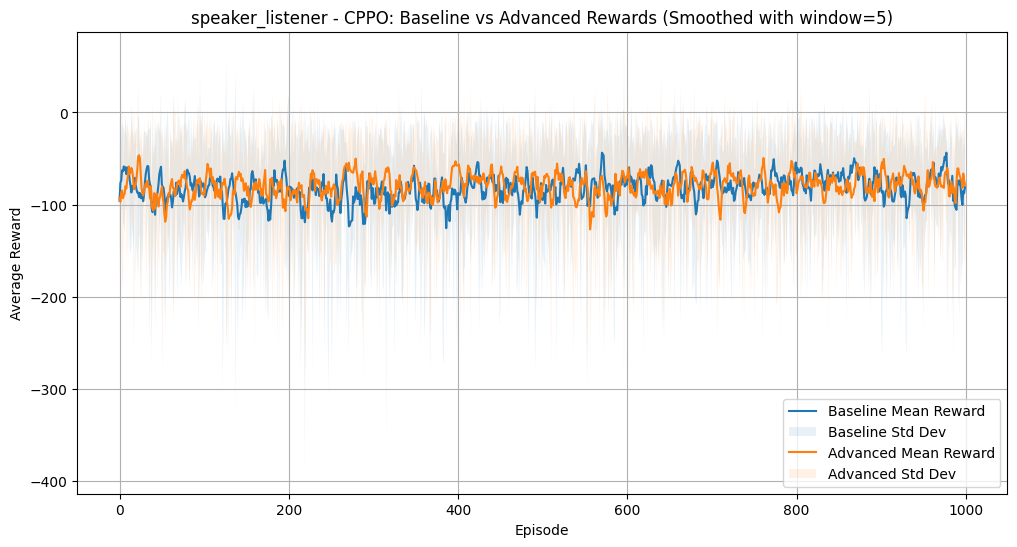

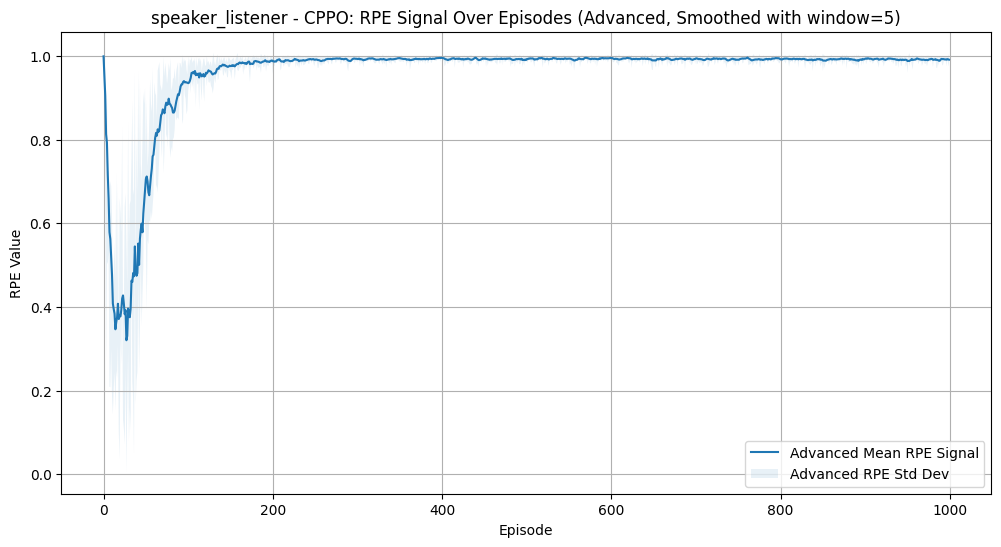

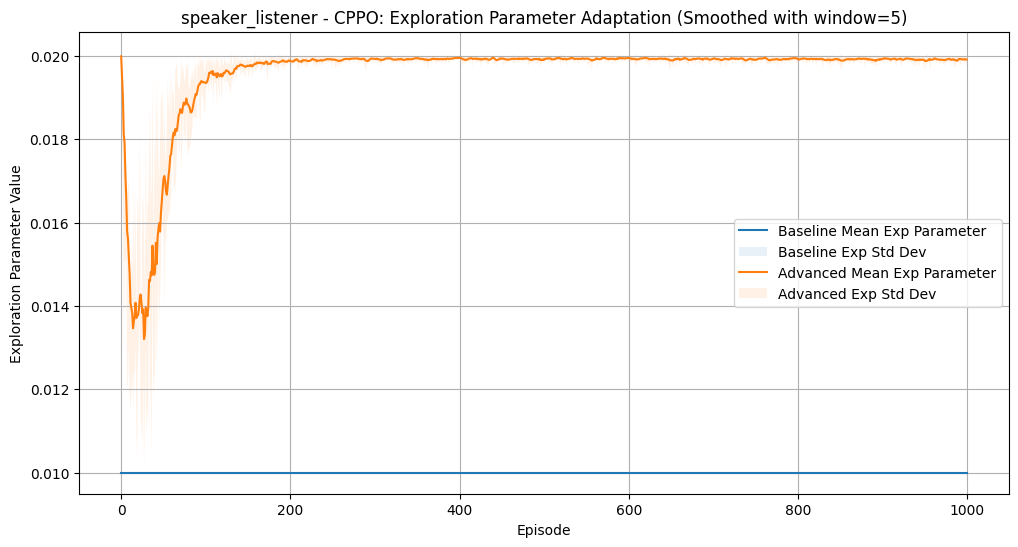

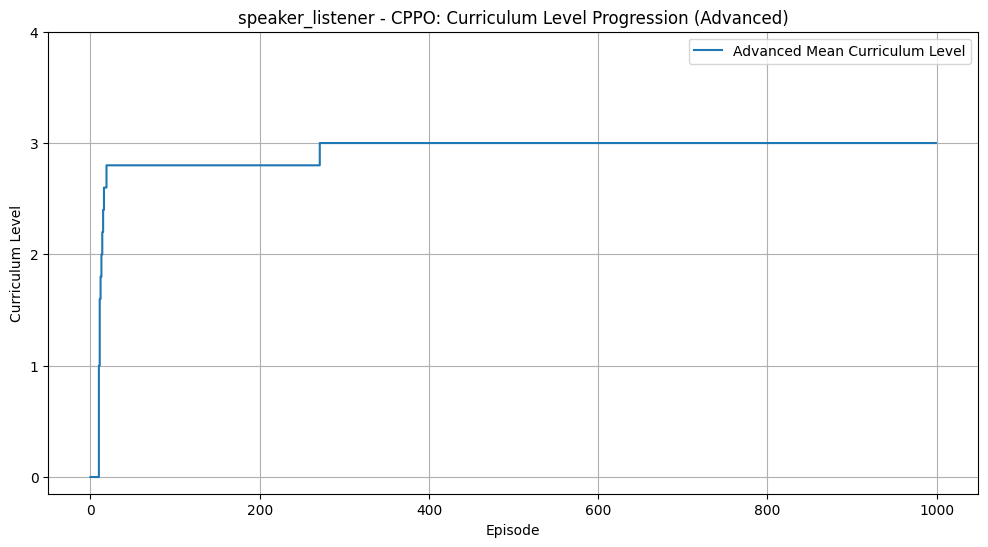

In [ ]:
print("\n--- Running CPPO with new test parameters ---")
evaluate_algorithm(
    algo_name="CPPO",
    envs=envs_all,
    seeds=[0,1,2,3,4],
    episodes=1000,
    max_steps=25
)